# EDA completa — CICDDoS2019 (ClickHouse + Spark)

**Estratégia:** o SQL roda no ClickHouse sobre o dataset **inteiro** (todas as tabelas `data*`, via `UNION ALL`)
e devolve apenas agregados pequenos. O Pandas só recebe uma **amostra estratificada por classe**, usada para gráficos,
correlação e comparações visuais.

| Nº | Análise | Onde roda |
|----|---------|-----------|
| 1 | Dimensão do dataset (tabelas, registros, colunas) | SQL – dataset inteiro |
| 2 | Registros por classe / target binário | SQL – dataset inteiro |
| 3 | Tipos das features | SQL (schema + inferência) |
| 4 | Valores nulos / vazios | SQL – dataset inteiro |
| 5 | NaN / +Inf / −Inf / não numéricos | SQL – dataset inteiro |
| 6 | Duplicatas | SQL – dataset inteiro |
| 7 | Features constantes / baixa variabilidade | SQL – dataset inteiro |
| 8 | Estatísticas descritivas (min, max, média, mediana, desvio, Q1, Q3) | SQL – dataset inteiro |
| 9 | Outliers (IQR, só identificação) | SQL – dataset inteiro |
| 10 | Correlação | Pandas – amostra |
| 11 | Distribuições e Feature × Classe | SQL (medianas) + Pandas – amostra |

> **EDA identifica, pré-processamento decide.** Nada é removido ou alterado aqui.

Todos os resultados são salvos em `eda_outputs/` (CSV) — se o kernel cair, basta reexecutar: etapas concluídas vêm do cache.

**Modo seguro (padrão):** 1 coluna por consulta, memória mínima, conexão direta por HTTP e progresso salvo a cada poucas unidades (com estimativa de tempo). É mais lento, mas não perde trabalho se algo parar.

**Cada análise pesada só termina quando está 100% completa.** O motor `completar()` mede, detecta lacunas (por exemplo, uma
feature que estourou a memória do servidor numa tabela), refaz só as lacunas em novas rodadas (1 coluna por vez, memória mínima,
com espera entre rodadas) e, se ainda faltar algo, **interrompe a execução com erro** — assim as células seguintes nunca rodam
sobre dados incompletos. O progresso fica salvo em `<nome>.parcial.csv`; basta rodar a mesma célula de novo para retomar.
`REFAZER = True` apaga todos os caches (volte para `False` depois).

> **Servidor com pouca memória:** o limite do ClickHouse também é consumido por *merges internos* (por exemplo de `system.metric_log`).
> O notebook verifica `system.merges` antes de insistir depois de uma falha e espera esses merges terminarem (`ESPERAR_MERGES`).

## 0. Configuração (ambiente, driver JDBC e Spark)

In [1]:
import os
import urllib.request
from pathlib import Path

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()


def load_env(path: Path) -> dict:
    values = {}
    for line in path.read_text().splitlines():
        line = line.strip()
        if not line or line.startswith("#") or "=" not in line:
            continue
        key, _, value = line.partition("=")
        values[key.strip()] = value.strip().strip('"').strip("'")
    return values


env_path = REPO_ROOT / ".env"
if not env_path.exists():
    raise FileNotFoundError(f"Arquivo .env não encontrado em: {env_path}")

env = {**load_env(env_path), **os.environ}

CH_HOST = env["CLICKHOUSE_HOST"]
CH_PORT = env["CLICKHOUSE_PORT"]
CH_USER = env["CLICKHOUSE_USER"]
CH_PASSWORD = env["CLICKHOUSE_PASSWORD"]
CH_DATABASE = env["CLICKHOUSE_DATABASE"]

JDBC_URL = f"jdbc:clickhouse://{CH_HOST}:{CH_PORT}/{CH_DATABASE}?ssl=true"
print(f"ClickHouse: {CH_HOST}:{CH_PORT}/{CH_DATABASE}  |  usuário: {CH_USER}")

ClickHouse: clickhouse-production-e204.up.railway.app:443/railway  |  usuário: clickhouse


In [2]:
CLICKHOUSE_JDBC_VERSION = "0.8.6"

JDBC_DIR = REPO_ROOT / "jars"
JDBC_DIR.mkdir(exist_ok=True)
JDBC_JAR = JDBC_DIR / f"clickhouse-jdbc-{CLICKHOUSE_JDBC_VERSION}-shaded-all.jar"

if not JDBC_JAR.exists():
    url = (
        "https://repo1.maven.org/maven2/com/clickhouse/clickhouse-jdbc/"
        f"{CLICKHOUSE_JDBC_VERSION}/{JDBC_JAR.name}"
    )
    print("Baixando driver JDBC...")
    urllib.request.urlretrieve(url, JDBC_JAR)

print("JDBC:", JDBC_JAR, "| existe:", JDBC_JAR.exists())

JDBC: C:\Users\Bruno\downloads\tcc_codigo\railway-ch\jars\clickhouse-jdbc-0.8.6-shaded-all.jar | existe: True


In [3]:
from pyspark.sql import SparkSession

# Configuração do Hadoop para Windows (remova se não for Windows)
os.environ["HADOOP_HOME"] = r"C:\hadoop"
os.environ["hadoop.home.dir"] = r"C:\hadoop"
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"
os.environ["PYSPARK_SUBMIT_ARGS"] = f'--jars "{JDBC_JAR}" pyspark-shell'

spark = (
    SparkSession.builder
    .appName("ddos-exploratory-analysis")
    .master("local[*]")
    .config("spark.driver.memory", "4g")   # a amostra é coletada no driver
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.ui.showConsoleProgress", "false")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
print("Spark:", spark.version)

Spark: 4.2.0


## 1. Funções auxiliares

In [4]:
import time, json, http.client, urllib.request, urllib.parse, urllib.error
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

# ------------------------- parâmetros gerais -------------------------
REFAZER = False             # True = APAGA os caches e recalcula tudo (volte a False depois)
AMOSTRA_POR_CLASSE = 10_000 # linhas (aprox.) por label na amostra do Pandas
MODO_SEGURO = False         # True = memória mínima SEMPRE (bem mais lento). False = rápido na 1ª rodada; mínima nas seguintes
THREADS = 2                 # threads do ClickHouse na 1ª rodada (se o servidor tiver núcleos sobrando, pode subir)
COLS_POR_CONSULTA = 4       # nº de features por consulta nas estatísticas/outliers (a divisão automática protege)
ESPERAR_MERGES = True       # espera merges INTERNOS do ClickHouse (ex.: system.metric_log) terminarem antes de tentar de novo
LIMITE_MERGE_MIB = 300      # considera 'servidor ocupado' se os merges usarem mais que isto
ESPERA_MERGE_MAX = 600      # segundos máximos esperando cada vez
LINHAS_POR_BUCKET = 3_000_000   # duplicatas: máx. de grupos por consulta (menor = menos memória, mais consultas)
USAR_TABELAS_AUXILIARES = True  # duplicatas: grava hashes compactos em tabelas eda_tmp_hash_* (precisa de permissão CREATE)
TOTAL_ENTRE_TABELAS = False      # False = não mede duplicatas ENTRE tabelas (TOTAL vira a soma por tabela)
LIMPAR_AUX_AO_FINAL = True      # apaga as tabelas auxiliares quando a análise de duplicatas fecha
PREFIXO_AUX = "eda_tmp_hash_"
LOTE = 10                   # unidades medidas entre dois salvamentos do progresso (checkpoint)
VERBOSO = False             # True = imprime uma linha por consulta
USAR_HTTP = True            # True = fala direto com o ClickHouse por HTTP (sem Spark); False = Spark/JDBC
HTTP_TIMEOUT = 1800         # segundos máximos de espera por uma consulta
CH_SCHEME = globals().get("CH_SCHEME", "https")
# Servidor com pouca RAM (ex.: 3 GiB): poucas threads + spill em disco no GROUP BY
CH_SETTINGS = "SETTINGS max_threads = 1, max_bytes_before_external_group_by = 400000000, max_block_size = 8192"
LIMIAR_CORR = 0.95
SEMENTE = 42

OUT = REPO_ROOT / "eda_outputs"
FIG = OUT / "figuras"
FIG.mkdir(parents=True, exist_ok=True)

if REFAZER:   # CUIDADO: apaga todos os resultados em cache. Volte REFAZER para False depois desta execução.
    for _p in [*OUT.glob("*.csv"), *OUT.glob("*.csv.gz"), *OUT.glob("*.parquet")]:
        _p.unlink()
    print("REFAZER = True: caches de eda_outputs/ apagados. Volte REFAZER para False após esta execução.")


def _executar_spark(query: str) -> pd.DataFrame:
    # Via Spark/JDBC (plano B). Tudo volta como texto/objeto.
    df = (
        spark.read.format("jdbc")
        .option("url", JDBC_URL)
        .option("query", query)
        .option("user", CH_USER)
        .option("password", CH_PASSWORD)
        .option("driver", "com.clickhouse.jdbc.ClickHouseDriver")
        .load()
    )
    rows = df.collect()
    return pd.DataFrame([r.asDict() for r in rows], columns=df.columns)


class ErroConexao(Exception):
    """Falha de rede/servidor indisponível, mesmo após várias tentativas (erro transitório)."""


CONEXAO_ESPERAS = (0, 5, 15, 45, 90)   # segundos de espera antes de cada nova tentativa de conexão
_conn = None                           # conexão HTTP reutilizada entre consultas (evita novo handshake TLS)


def _fechar_conexao():
    global _conn
    try:
        if _conn is not None:
            _conn.close()
    except Exception:
        pass
    _conn = None


def _executar_http(query: str) -> pd.DataFrame:
    # HTTP direto (stdlib). Reaproveita a conexão e, se a rede cair (reset, timeout, handshake TLS recusado,
    # 502/503/504), reconecta e tenta de novo com espera crescente. Erros do servidor viram Exception com o texto original.
    global _conn
    caminho = "/?" + urllib.parse.urlencode({"database": CH_DATABASE, "default_format": "JSONCompact",
                                             "wait_end_of_query": 1})
    cab = {"X-ClickHouse-User": CH_USER, "X-ClickHouse-Key": CH_PASSWORD, "Connection": "keep-alive"}
    ultimo = None
    for espera in CONEXAO_ESPERAS:
        if espera:
            print(f"  ⚠ conexão instável ({type(ultimo).__name__}); nova tentativa em {espera}s...")
            time.sleep(espera)
        try:
            if _conn is None:
                cls = http.client.HTTPSConnection if CH_SCHEME == "https" else http.client.HTTPConnection
                _conn = cls(CH_HOST, int(CH_PORT), timeout=HTTP_TIMEOUT)
            _conn.request("POST", caminho, body=query.encode("utf-8"), headers=cab)
            resp = _conn.getresponse()
            corpo = resp.read()
        except (OSError, http.client.HTTPException) as e:   # reset, timeout, SSL, desconexão no meio
            ultimo = e
            _fechar_conexao()
            continue
        if resp.status in (502, 503, 504) or (resp.status >= 500 and not corpo.startswith(b"Code:")):
            ultimo = Exception(f"HTTP {resp.status}")
            _fechar_conexao()
            continue
        if resp.status != 200:                               # erro de SQL/servidor: texto original do ClickHouse
            raise Exception(corpo.decode("utf-8", "replace")[:2000])
        if not corpo.strip():                                # DDL / INSERT: resposta vazia
            return pd.DataFrame()
        dados = json.loads(corpo)
        return pd.DataFrame(dados.get("data", []), columns=[m["name"] for m in dados.get("meta", [])])
    raise ErroConexao(f"Sem conexão com o ClickHouse após {len(CONEXAO_ESPERAS)} tentativas: {ultimo!r}")


_http_ok = None


def _executar(query: str) -> pd.DataFrame:
    global _http_ok
    if USAR_HTTP and _http_ok is None:   # testa uma vez; se falhar, cai para Spark
        try:
            _executar_http("SELECT 1")
            _http_ok = True
            print("Transporte: HTTP direto (sem Spark)")
        except Exception as e:
            _http_ok = False
            print(f"Transporte: HTTP indisponível ({str(e).splitlines()[0][:100]}); usando Spark/JDBC")
    return _executar_http(query) if (USAR_HTTP and _http_ok) else _executar_spark(query)


def ch(query: str) -> pd.DataFrame:
    t0 = time.time()
    if "SETTINGS" not in query:
        query = query.rstrip().rstrip(";") + "\n" + CH_SETTINGS
    res = _executar(query)
    dt = time.time() - t0
    if VERBOSO or dt > 60:
        print(f"  [{dt:6.1f}s] {len(res)} linha(s) x {res.shape[1]} coluna(s)")
    return res


def num(df: pd.DataFrame, cols=None) -> pd.DataFrame:
    # Converte colunas (texto) para número; o que não converte vira NaN.
    df = df.copy()
    for c in (cols if cols is not None else df.columns):
        df[c] = pd.to_numeric(df[c], errors="coerce")
    return df


def cached(nome: str, fn):
    # Lê eda_outputs/<nome>.csv se existir; senão calcula com fn() e salva.
    p = OUT / f"{nome}.csv"
    if p.exists() and not REFAZER:
        print(f"[cache] {nome}")
        return pd.read_csv(p, keep_default_na=False, na_values=[""])
    print(f"[calculando] {nome}")
    res = fn()
    res.to_csv(p, index=False)
    return res


def salvar_fig(nome: str):
    plt.tight_layout()
    plt.savefig(FIG / f"{nome}.png", dpi=130, bbox_inches="tight")
    plt.show()


def blocos(lista, n):
    for i in range(0, len(lista), n):
        yield lista[i:i + n]



_RECUPERAVEIS = ("MEMORY_LIMIT_EXCEEDED", "memory limit exceeded", "timed out", "TimeoutError",
                 "Connection reset", "Connection aborted", "RemoteDisconnected", "BrokenPipe", "Broken pipe",
                 "TOO_MANY_SIMULTANEOUS_QUERIES", "Connection refused", "Service Unavailable",
                 "Bad Gateway", "Gateway Time-out", "temporarily unavailable")


_RECUPERAVEIS_EXTRA = ("WinError 10054", "WinError 10053", "WinError 10060", "ConnectionResetError", "ConnectionError",
                       "forçado o cancelamento", "EOF occurred", "SSLError", "RemoteDisconnected", "IncompleteRead")


def erro_memoria(e) -> bool:
    # Erros TRANSITÓRIOS (memória, timeout, conexão): a unidade fica para a próxima rodada.
    # Qualquer outro erro (SQL inválido, senha errada...) é bug de verdade e interrompe tudo.
    if isinstance(e, (ErroConexao, OSError, http.client.HTTPException)):
        return True
    m = str(e)
    return any(p in m for p in _RECUPERAVEIS + _RECUPERAVEIS_EXTRA)


# Configuração de memória mínima (em MODO_SEGURO vale para todas as rodadas).
SETTINGS_MINIMOS = ("SETTINGS max_threads = 1, max_block_size = 1024, "
                    "max_read_buffer_size = 131072, max_bytes_before_external_group_by = 100000000")
MAX_RODADAS = 8              # nº máximo de passadas para fechar as lacunas de uma análise
ESPERA_ENTRE_RODADAS = 20    # segundos (x nº da rodada - 1) para o servidor liberar memória
PAUSA_DIVISAO = 2            # segundos de pausa ao dividir um bloco de colunas


SETTINGS_RAPIDOS = (f"SETTINGS max_threads = {THREADS}, max_block_size = 8192, "
                    "max_bytes_before_external_group_by = 400000000")


def sett(rodada: int) -> str:
    # 1ª rodada: configuração rápida. Rodadas seguintes (ou MODO_SEGURO): memória mínima.
    return SETTINGS_MINIMOS if (MODO_SEGURO or rodada > 1) else SETTINGS_RAPIDOS


_calma_ok = True
_POLL_MERGES = 10    # segundos entre verificações


def _esperar_calma():
    # O limite de memória do servidor também é consumido por merges INTERNOS (ex.: system.metric_log pode usar >1 GiB).
    # Antes de insistir depois de uma falha, espera esses merges baixarem (até ESPERA_MERGE_MAX).
    global _calma_ok
    if not (ESPERAR_MERGES and _calma_ok):
        return
    t0, avisou = time.time(), False
    while True:
        try:
            r = _executar("SELECT toString(sum(memory_usage)) AS m FROM system.merges")
            mib = float(r["m"][0] or 0) / 2 ** 20
        except Exception as e:
            if not erro_memoria(e):
                _calma_ok = False       # sem permissão para ler system.merges: desativa a guarda
            return
        if mib < LIMITE_MERGE_MIB or time.time() - t0 > ESPERA_MERGE_MAX:
            if avisou:
                print("  merges internos terminaram (ou tempo máximo atingido); seguindo")
            return
        if not avisou:
            print(f"  ⏳ ClickHouse com merges internos usando {mib:,.0f} MiB; aguardando terminarem "
                  f"(máx {ESPERA_MERGE_MAX}s)...")
            avisou = True
        time.sleep(_POLL_MERGES)


def com_divisao(cols, fn, rotulo=""):
    # Executa fn(cols). Se faltar memória, divide as colunas ao meio e tenta de novo.
    # Se uma única coluna falhar, devolve [] (a lacuna será tratada pelo completar()).
    try:
        return [fn(cols)]
    except Exception as e:
        if not erro_memoria(e):
            raise
        if len(cols) > 1:
            meio = len(cols) // 2
            print(f"  ⚠ memória insuficiente com {len(cols)} colunas ({rotulo}); dividindo ({meio} + {len(cols) - meio})")
            _esperar_calma()
            time.sleep(PAUSA_DIVISAO)
            return com_divisao(cols[:meio], fn, rotulo) + com_divisao(cols[meio:], fn, rotulo)
        print(f"  ✖ {cols[0]} ({rotulo}): sem memória; fica para a próxima rodada")
        return []


def _fmt(seg: float) -> str:
    seg = int(seg)
    return f"{seg // 3600}h{(seg % 3600) // 60:02d}min" if seg >= 3600 else f"{seg // 60}min{seg % 60:02d}s"


def completar(nome, esperado, medir, chaves, ext="csv", lote=None):
    # Garante que a análise `nome` seja medida para TODAS as unidades em `esperado`.
    #   esperado : lista de chaves (ex.: (tabela, feature)) que precisam existir no resultado
    #   medir    : medir(faltantes, rodada) -> DataFrame só com o que conseguiu medir (ou None)
    #   chaves   : chaves(df) -> conjunto de chaves presentes em df
    # - O progresso é SALVO a cada `lote` unidades em <nome>.parcial.<ext>: se o notebook parar,
    #   rodar a mesma célula retoma de onde parou, sem perder nada.
    # - Mostra progresso e tempo restante estimado.
    # - Unidades que falham por erro transitório (memória, timeout, conexão) ficam para a rodada seguinte
    #   (com espera). Se ainda faltar algo ao final, LEVANTA ERRO: as células seguintes não devem rodar.
    lote = lote or LOTE
    final, parcial = OUT / f"{nome}.{ext}", OUT / f"{nome}.parcial.{ext}"
    ler = lambda p: pd.read_csv(p, keep_default_na=False, na_values=[""])
    if not esperado:
        return pd.DataFrame()
    df = None
    for p in (final, parcial):
        if p.exists():
            df = ler(p)
            break
    presentes = chaves(df) if df is not None else set()
    faltam = [k for k in esperado if k not in presentes]
    if df is not None and not faltam and final.exists():
        print(f"[cache] {nome}: completo ({len(esperado)} unidades)")
        return df
    if df is not None:
        print(f"[retomando] {nome}: {len(esperado) - len(faltam)}/{len(esperado)} unidades já medidas")
    else:
        print(f"[calculando] {nome}: {len(esperado)} unidades")

    for rodada in range(1, MAX_RODADAS + 1):
        presentes = chaves(df) if df is not None else set()
        faltam = [k for k in esperado if k not in presentes]
        if not faltam:
            break
        print(f"[{nome}] rodada {rodada}/{MAX_RODADAS}: {len(faltam)} unidade(s) a medir")
        if rodada > 1:
            espera = ESPERA_ENTRE_RODADAS * (rodada - 1)
            print(f"  aguardando {espera}s para o servidor se recuperar...")
            time.sleep(espera)
        _esperar_calma()
        t_ini, t_print = time.time(), 0.0
        for i in range(0, len(faltam), lote):
            novo = medir(faltam[i:i + lote], rodada)
            if novo is not None and len(novo):
                df = novo if df is None else pd.concat([df, novo], ignore_index=True)
                df.to_csv(parcial, index=False)          # checkpoint
            feitos = min(i + lote, len(faltam))
            agora = time.time()
            if agora - t_print >= 15 or feitos == len(faltam):
                dec = agora - t_ini
                resto = dec / feitos * (len(faltam) - feitos)
                print(f"  {feitos}/{len(faltam)} ({feitos / len(faltam):.0%}) | decorrido {_fmt(dec)} | restante ~{_fmt(resto)}")
                t_print = agora

    presentes = chaves(df) if df is not None else set()
    faltam = [k for k in esperado if k not in presentes]
    if faltam:
        amostra_f = ", ".join(str(k) for k in faltam[:12]) + (" ..." if len(faltam) > 12 else "")
        raise RuntimeError(
            f"ANÁLISE '{nome}' INCOMPLETA: {len(faltam)} de {len(esperado)} unidades sem medição após "
            f"{MAX_RODADAS} rodadas: {amostra_f}\n"
            "O progresso foi salvo. Rode ESTA MESMA célula de novo para retomar de onde parou "
            "(antes, rode diagnostico_servidor() e libere memória no ClickHouse, ou aumente a memória do serviço). "
            "As células seguintes NÃO devem ser executadas até esta fechar."
        )
    df.to_csv(final, index=False)
    if parcial.exists():
        parcial.unlink()
    print(f"✔ [{nome}] completo: {len(esperado)} unidades")
    return df


def _mostrar(titulo, query):
    try:
        r = _executar(query)
        print(f"\n== {titulo} ==")
        print(r.to_string(index=False) if len(r) else "(nenhum)")
    except Exception as e:
        print(f"\n== {titulo} == (indisponível: {str(e).splitlines()[0][:110]})")


def diagnostico_servidor():
    # O que está consumindo a memória do ClickHouse? Rode também quando uma consulta falhar.
    _mostrar("Memória (processo)", '''
        SELECT metric, formatReadableSize(value) AS valor FROM system.asynchronous_metrics
        WHERE metric IN ('MemoryResident', 'OSMemoryTotal', 'MarkCacheBytes', 'UncompressedCacheBytes')
    ''')
    _mostrar("Rastreamento de memória (queries + merges + caches)", '''
        SELECT metric, formatReadableSize(value) AS valor FROM system.metrics
        WHERE metric IN ('MemoryTracking', 'BackgroundMergesAndMutationsPoolTask', 'Merge')
    ''')
    _mostrar("Merges em andamento", '''
        SELECT table, round(progress, 2) AS progresso, formatReadableSize(memory_usage) AS memoria
        FROM system.merges
    ''')
    _mostrar("Consultas em execução", '''
        SELECT elapsed, formatReadableSize(memory_usage) AS memoria, substring(query, 1, 70) AS consulta
        FROM system.processes
    ''')


diagnostico_servidor()

Transporte: HTTP direto (sem Spark)

== Memória (processo) ==
        metric      valor
 OSMemoryTotal 251.70 GiB
MemoryResident   1.75 GiB

== Rastreamento de memória (queries + merges + caches) ==
                              metric      valor
                               Merge     0.00 B
BackgroundMergesAndMutationsPoolTask     0.00 B
                      MemoryTracking 529.51 MiB

== Merges em andamento ==
     table  progresso  memoria
metric_log          0   0.00 B
metric_log          0 2.36 MiB

== Consultas em execução ==
 elapsed   memoria                                                                consulta
 15.9194 77.36 MiB \n                    SELECT toString(sum(n)) AS registros, toString(su
  0.0012  3.09 MiB \n        SELECT elapsed, formatReadableSize(memory_usage) AS memoria, 


## 2. Análise 1 — Dimensão do dataset

**Pergunta:** "O que exatamente temos em mãos?" Quais tabelas existem, quantos registros cada uma tem,
se o *schema* é igual entre elas e quantas colunas/features existem de fato.

In [5]:
# 1.1 Tabelas existentes
tabelas_meta = ch('''
SELECT name AS tabela, engine, toString(total_rows) AS total_rows_meta
FROM system.tables
WHERE database = currentDatabase() AND name LIKE 'data%'
ORDER BY name
''')

TABELAS = tabelas_meta["tabela"].tolist()
print(len(TABELAS), "tabelas encontradas:")
display(tabelas_meta)

18 tabelas encontradas:


,tabela,engine,total_rows_meta
0,data2_ldap,MergeTree,2113234
1,data2_mssql,MergeTree,5775786
2,data2_netbios,MergeTree,3455899
3,data2_portmap,MergeTree,191694
4,data2_syn,MergeTree,4320541
5,data2_udp,MergeTree,3782206
6,data2_udplag,MergeTree,725165
7,data_drdos_dns,MergeTree,5074413
8,data_drdos_ldap,MergeTree,2181542
9,data_drdos_mssql,MergeTree,4524498


In [6]:
# 1.2 Registros por tabela (contagem exata, não a estimativa dos metadados)
def _medir_contagem(faltam, rodada):
    partes = []
    for t in faltam:
        try:
            partes.append(num(ch(f"SELECT '{t}' AS tabela, toString(count()) AS registros FROM `{t}`\n{sett(rodada)}"),
                              ["registros"]))
        except Exception as e:
            if not erro_memoria(e):
                raise
            print(f"  ✖ {t}: sem memória; fica para a próxima rodada")
    return pd.concat(partes, ignore_index=True) if partes else None


registros_tabela = completar("01_registros_por_tabela", TABELAS, _medir_contagem, lambda d: set(d["tabela"]), lote=1)
registros_tabela = registros_tabela.sort_values("tabela").reset_index(drop=True)
registros_tabela["percentual"] = registros_tabela["registros"] / registros_tabela["registros"].sum() * 100
TOTAL_REGISTROS = int(registros_tabela["registros"].sum())

display(registros_tabela)
print(f"\nTOTAL DE REGISTROS: {TOTAL_REGISTROS:,}")

[cache] 01_registros_por_tabela: completo (18 unidades)


,tabela,registros,percentual
0,data2_ldap,2113234,3.0006
1,data2_mssql,5775786,8.2010
2,data2_netbios,3455899,4.9070
3,data2_portmap,191694,0.2722
4,data2_syn,4320541,6.1347
5,data2_udp,3782206,5.3703
6,data2_udplag,725165,1.0297
7,data_drdos_dns,5074413,7.2051
8,data_drdos_ldap,2181542,3.0976
9,data_drdos_mssql,4524498,6.4243



TOTAL DE REGISTROS: 70,427,637


In [7]:
# 1.3 Schema por tabela: as colunas são as mesmas em todas as tabelas?
def _schema():
    lista = ", ".join(f"'{t}'" for t in TABELAS)
    return ch(f'''
        SELECT table AS tabela, name AS coluna, type AS tipo, toString(position) AS posicao
        FROM system.columns
        WHERE database = currentDatabase() AND table IN ({lista})
        ORDER BY table, position
    ''')


schema = cached("01_schema", _schema)

colunas_por_tabela = schema.groupby("tabela")["coluna"].apply(set)
COLUNAS_COMUNS = [c for c in schema[schema.tabela == TABELAS[0]].sort_values("posicao")["coluna"]
                  if all(c in s for s in colunas_por_tabela)]
todas = set().union(*colunas_por_tabela)
divergentes = sorted(todas - set(COLUNAS_COMUNS))

print(f"Colunas na 1ª tabela: {len(colunas_por_tabela.iloc[0])} | colunas comuns a TODAS as tabelas: {len(COLUNAS_COMUNS)}")
if divergentes:
    print("\n⚠ Colunas que NÃO existem em todas as tabelas (ficam fora da análise):")
    for c in divergentes:
        faltam = [t for t in TABELAS if c not in colunas_por_tabela[t]]
        print(f"  - {c}: ausente em {faltam}")
else:
    print("✔ Todas as tabelas têm exatamente o mesmo conjunto de colunas.")

tipos_diferentes = schema.groupby("coluna")["tipo"].nunique()
tipos_diferentes = tipos_diferentes[tipos_diferentes > 1]
if len(tipos_diferentes):
    print("\n⚠ Colunas com tipo diferente entre tabelas:", list(tipos_diferentes.index))

[cache] 01_schema
Colunas na 1ª tabela: 88 | colunas comuns a TODAS as tabelas: 88
✔ Todas as tabelas têm exatamente o mesmo conjunto de colunas.


In [8]:
# 1.4 Papel de cada coluna: identificador, target ou feature
COL_LABEL = "label"
COLUNAS_ID = [c for c in ["unnamed_0", "flow_id", "source_ip", "source_port",
                          "destination_ip", "destination_port", "timestamp"] if c in COLUNAS_COMUNS]
FEATURES = [c for c in COLUNAS_COMUNS if c not in COLUNAS_ID and c != COL_LABEL]

# Target binário: BENIGN -> 0 (benigno) | qualquer outro -> 1 (ataque)
ALVO_SQL = f"if(upper(trimBoth(`{COL_LABEL}`)) = 'BENIGN', 'benigno', 'ataque')"

print(f"Colunas totais (comuns): {len(COLUNAS_COMUNS)}")
print(f"  identificadores (NÃO usar como feature): {COLUNAS_ID}")
print(f"  target: {COL_LABEL}")
print(f"  features candidatas: {len(FEATURES)}")

dimensao = pd.DataFrame({
    "item": ["Tabelas", "Registros", "Colunas (comuns)", "Identificadores", "Features candidatas", "Target"],
    "valor": [len(TABELAS), f"{TOTAL_REGISTROS:,}", len(COLUNAS_COMUNS), len(COLUNAS_ID), len(FEATURES), COL_LABEL],
})
display(dimensao)

Colunas totais (comuns): 88
  identificadores (NÃO usar como feature): ['unnamed_0', 'flow_id', 'source_ip', 'source_port', 'destination_ip', 'destination_port', 'timestamp']
  target: label
  features candidatas: 80


,item,valor
0,Tabelas,18
1,Registros,"70,427,637"
2,Colunas (comuns),88
3,Identificadores,7
4,Features candidatas,80
5,Target,label


In [9]:
# Fonte única: UNION ALL de todas as tabelas. Tudo é convertido para String para evitar
# conflito de tipos entre tabelas e porque o schema original já é String.
def src(cols, texto=True, tabelas=None):
    tabelas = tabelas or TABELAS
    sel = ", ".join((f"toString(`{c}`) AS `{c}`" if texto else f"`{c}`") for c in cols)
    partes = [f"SELECT '{t}' AS _tabela, {sel} FROM `{t}`" for t in tabelas]
    return "(" + " UNION ALL ".join(partes) + ")"


INF_POS = "'inf','+inf','infinity','+infinity'"
INF_NEG = "'-inf','-infinity'"

## 3. Análise 2 — Registros por classe e target binário

Mostra o problema que o *Hybrid Sampling* precisa resolver: desbalanceamento entre as classes.

In [10]:
LIMITE_CARDINALIDADE = 500


def _medir_classes(faltam, rodada):
    # Se o label tiver cardinalidade absurda (ex.: colunas deslocadas na importação), não agrega:
    # registra a tabela como <<ALTA CARDINALIDADE>> (achado da EDA) e segue.
    partes = []
    for t in faltam:
        try:
            d = num(ch(f'''
                SELECT toString(count()) AS n, toString(uniq(`{COL_LABEL}`)) AS distintos,
                       toString(topK(5)(`{COL_LABEL}`)) AS exemplos
                FROM `{t}`
                {sett(rodada)}
            '''), ["n", "distintos"])
            n, distintos, exemplos = int(d.n[0]), int(d.distintos[0]), d.exemplos[0]
            if distintos > LIMITE_CARDINALIDADE:
                print(f"  ⚠ {t}: label com ~{distintos:,} valores distintos; exemplos: {exemplos}")
                partes.append(pd.DataFrame({"tabela": [t], "label": [f"<<ALTA CARDINALIDADE ~{distintos}>>"], "registros": [n]}))
                continue
            partes.append(num(ch(f'''
                SELECT '{t}' AS tabela, `{COL_LABEL}` AS label, toString(count()) AS registros
                FROM `{t}` GROUP BY `{COL_LABEL}`
                {sett(rodada)}
            '''), ["registros"]))
        except Exception as e:
            if not erro_memoria(e):
                raise
            print(f"  ✖ {t}: sem memória; fica para a próxima rodada")
    return pd.concat(partes, ignore_index=True) if partes else None


classes_tabela = completar("02_classes_por_tabela", TABELAS, _medir_classes, lambda d: set(d["tabela"]), lote=1)
classes_tabela["label_norm"] = classes_tabela["label"].astype(str).str.strip()

# Labels "crus" que diferem só por maiúscula/espaço indicariam sujeira no rótulo
brutos = classes_tabela["label"].astype(str).unique()
norm = {l.strip().upper() for l in brutos}
if len(norm) != len(set(brutos)):
    print("⚠ Há labels que diferem só por caixa/espaços:", sorted(brutos))

distribuicao = (classes_tabela.groupby("label_norm", as_index=False)["registros"].sum()
                .sort_values("registros", ascending=False).reset_index(drop=True))
distribuicao["percentual"] = distribuicao["registros"] / distribuicao["registros"].sum() * 100
distribuicao["alvo"] = np.where(distribuicao["label_norm"].str.upper() == "BENIGN", 0, 1)

print(f"{len(distribuicao)} classes distintas")
display(distribuicao)

binario = distribuicao.groupby("alvo")["registros"].sum()
n_ben, n_atk = int(binario.get(0, 0)), int(binario.get(1, 0))
print(f"\nTARGET BINÁRIO -> benigno (0): {n_ben:,} ({n_ben / TOTAL_REGISTROS:.4%}) | ataque (1): {n_atk:,} ({n_atk / TOTAL_REGISTROS:.4%})")
if n_ben:
    print(f"Razão ataque:benigno = {n_atk / n_ben:,.1f} : 1")

[cache] 02_classes_por_tabela: completo (18 unidades)
19 classes distintas


,label_norm,registros,percentual,alvo
0,TFTP,20082580,28.5152,1
1,Syn,6473789,9.1921,1
2,MSSQL,5787453,8.2176,1
3,DrDoS_SNMP,5159870,7.3265,1
4,DrDoS_DNS,5071011,7.2003,1
5,DrDoS_MSSQL,4522492,6.4215,1
6,DrDoS_NetBIOS,4093279,5.8120,1
7,UDP,3867155,5.4910,1
8,NetBIOS,3657497,5.1933,1
9,DrDoS_UDP,3134645,4.4509,1



TARGET BINÁRIO -> benigno (0): 113,828 (0.1616%) | ataque (1): 70,313,809 (99.8384%)
Razão ataque:benigno = 617.7 : 1


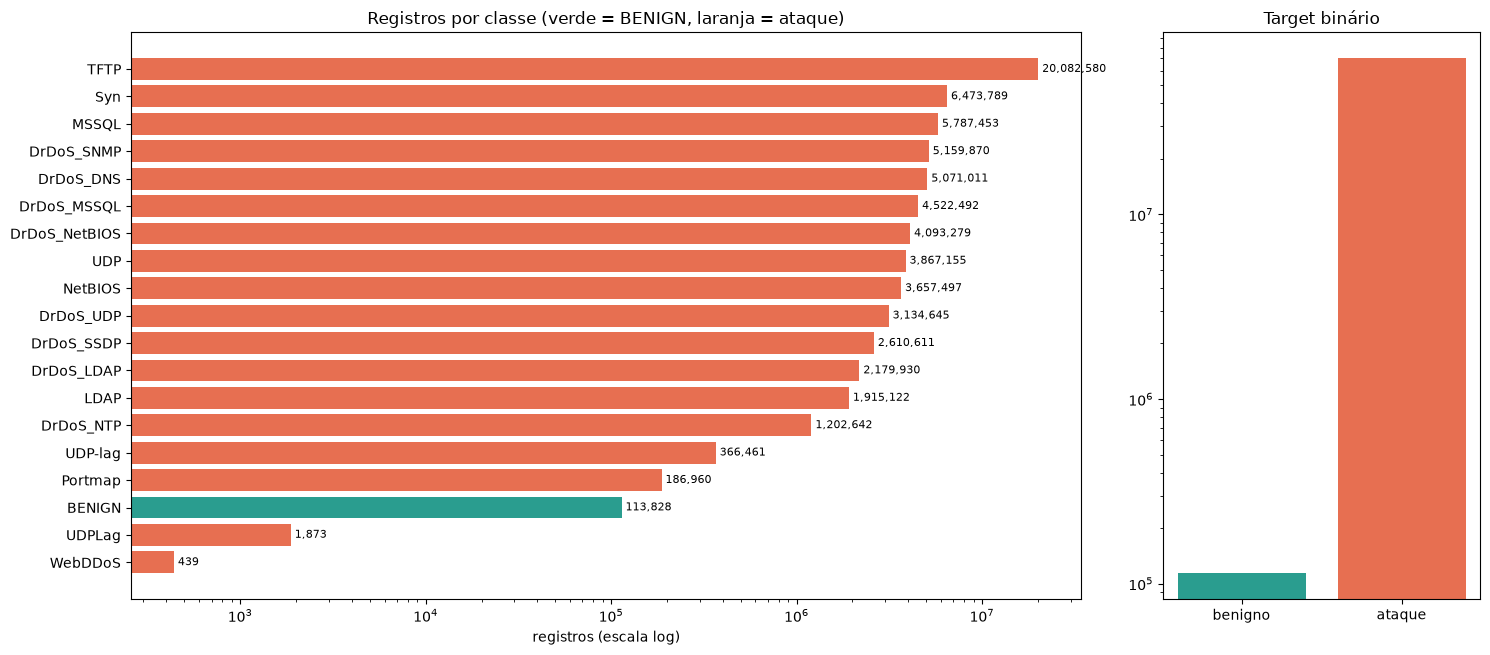

tabela,data2_ldap,data2_mssql,data2_netbios,data2_portmap,data2_syn,data2_udp,data2_udplag,data_drdos_dns,data_drdos_ldap,data_drdos_mssql,data_drdos_netbios,data_drdos_ntp,data_drdos_snmp,data_drdos_ssdp,data_drdos_udp,data_syn,data_tftp,data_udplag
label_norm,,,,,,,,,,,,,,,,,,
BENIGN,5124,2794,1321,4734,35790,3134,4068,3402,1612,2006,1707,14365,1507,763,2157,392,25247,3705
DrDoS_DNS,0,0,0,0,0,0,0,5071011,0,0,0,0,0,0,0,0,0,0
DrDoS_LDAP,0,0,0,0,0,0,0,0,2179930,0,0,0,0,0,0,0,0,0
DrDoS_MSSQL,0,0,0,0,0,0,0,0,0,4522492,0,0,0,0,0,0,0,0
DrDoS_NTP,0,0,0,0,0,0,0,0,0,0,0,1202642,0,0,0,0,0,0
DrDoS_NetBIOS,0,0,0,0,0,0,0,0,0,0,4093279,0,0,0,0,0,0,0
DrDoS_SNMP,0,0,0,0,0,0,0,0,0,0,0,0,5159870,0,0,0,0,0
DrDoS_SSDP,0,0,0,0,0,0,0,0,0,0,0,0,0,2610611,0,0,0,0
DrDoS_UDP,0,0,0,0,0,0,0,0,0,0,0,0,0,0,3134645,0,0,0


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(15, max(4, 0.35 * len(distribuicao))), gridspec_kw={"width_ratios": [3, 1]})

d = distribuicao.sort_values("registros")
cores = ["#2a9d8f" if a == 0 else "#e76f51" for a in d["alvo"]]
ax[0].barh(d["label_norm"], d["registros"], color=cores)
ax[0].set_xscale("log")
ax[0].set_xlabel("registros (escala log)")
ax[0].set_title("Registros por classe (verde = BENIGN, laranja = ataque)")
for y, v in enumerate(d["registros"]):
    ax[0].text(v, y, f" {int(v):,}", va="center", fontsize=8)

ax[1].bar(["benigno", "ataque"], [n_ben, n_atk], color=["#2a9d8f", "#e76f51"])
ax[1].set_yscale("log")
ax[1].set_title("Target binário")
salvar_fig("02_distribuicao_classes")

# Matriz tabela x classe (onde cada ataque mora)
display(classes_tabela.pivot_table(index="label_norm", columns="tabela", values="registros",
                                   aggfunc="sum", fill_value=0))

## 4. Análise 3 — Tipos das colunas

O *schema* declarado no ClickHouse é `String`; abaixo, além do tipo declarado, mostra-se o **tipo inferido**
pelo conteúdo (feito após a análise de qualidade, na seção 5).

In [12]:
tipos_declarados = (schema.groupby("coluna")["tipo"].agg(lambda s: ", ".join(sorted(set(s))))
                    .reindex(COLUNAS_COMUNS).reset_index())
tipos_declarados["papel"] = np.where(tipos_declarados["coluna"].isin(COLUNAS_ID), "identificador",
                             np.where(tipos_declarados["coluna"] == COL_LABEL, "target", "feature"))
print(tipos_declarados["tipo"].value_counts().to_string())
display(tipos_declarados)

tipo
String    88


,coluna,tipo,papel
0,unnamed_0,String,identificador
1,flow_id,String,identificador
2,source_ip,String,identificador
3,source_port,String,identificador
4,destination_ip,String,identificador
5,destination_port,String,identificador
6,protocol,String,feature
7,timestamp,String,identificador
8,flow_duration,String,feature
9,total_fwd_packets,String,feature


## 5. Análises 4 e 5 — Nulos/vazios, NaN e ±Infinity (e valores não numéricos)

Contagem **por feature e por tabela**, no dataset inteiro. Como as colunas são `String`, "nulo" = string vazia.
Um valor é classificado, mutuamente exclusivo, como: `vazio`, `nan`, `pos_inf`, `neg_inf`,
`nao_numerico` (texto que não converte para número) ou válido.

**Método (rápido e com memória controlada):** cada consulta lê um *grupo* de colunas de uma tabela **uma única vez**,
faz um único parse numérico por valor e só compara texto nos valores "suspeitos" (vazios, NaN, ±Inf, texto). As definições
de vazio / NaN / +Inf / −Inf / não numérico são exatamente as mesmas de antes (resultado idêntico, validado). Se faltar
memória, o grupo é dividido ao meio automaticamente até 1 coluna. Ajuste `QUAL_COLS_POR_CONSULTA` e `QUAL_THREADS` na célula abaixo.

In [13]:
# ============================================================
# ANÁLISES 4 e 5 — leitura única por grupo de colunas (rápida, memória controlada)
# ============================================================
# Antes: 6 consultas por (tabela, feature), 1 thread e pausa de 2s por unidade.
# Agora: cada consulta lê um GRUPO de colunas de uma tabela UMA vez:
#   - 1 parse numérico por valor; só os valores "suspeitos" (vazio, NaN, ±Inf, texto) passam pelas
#     comparações de texto (o AND é avaliado de forma preguiçosa pelo ClickHouse);
#   - definições IDÊNTICAS às anteriores de vazio / NaN / +Inf / -Inf / não numérico;
#   - se faltar memória, o grupo é dividido ao meio (até 1 coluna); as rodadas seguintes usam memória mínima.
QUAL_COLS_POR_CONSULTA = 8   # features por consulta (menor = mais cauteloso; 1 = máxima cautela)
QUAL_THREADS = 2             # threads do ClickHouse na 1ª rodada (as rodadas seguintes usam 1)


def _settings_qual(rodada):
    if rodada == 1:
        return f"SETTINGS max_threads = {QUAL_THREADS}, max_block_size = 8192"
    return SETTINGS_MINIMOS


def _consulta_qualidade(grupo, t, rodada):
    ex = []
    for c in grupo:
        x = f"`{c}`"
        susp = f"ifNull(isFinite(toFloat64OrNull({x})), 0) = 0"      # vazio, NaN, ±Inf ou texto (raros)
        ex += [
            f"toString(countIf({x} = '')) AS `{c}__vazio`",
            f"toString(countIf({susp} AND lower({x}) = 'nan')) AS `{c}__nan`",
            f"toString(countIf({susp} AND lower({x}) IN ({INF_POS}))) AS `{c}__pos_inf`",
            f"toString(countIf({susp} AND lower({x}) IN ({INF_NEG}))) AS `{c}__neg_inf`",
            (f"toString(countIf(isNull(toFloat64OrNull({x})) AND {x} != '' "
             f"AND lower({x}) NOT IN ('nan',{INF_POS},{INF_NEG}))) AS `{c}__nao_numerico`"),
        ]
    wide = ch(f"""
        SELECT toString(count()) AS total, {", ".join(ex)}
        FROM `{t}`
        {_settings_qual(rodada)}
    """)
    wide.insert(0, "tabela", t)
    long = wide.melt(id_vars=["tabela", "total"], var_name="chave", value_name="valor")
    long[["coluna", "metrica"]] = long["chave"].str.rsplit("__", n=1, expand=True)
    long["valor"] = pd.to_numeric(long["valor"])
    long["total"] = pd.to_numeric(long["total"])
    return long[["tabela", "total", "coluna", "metrica", "valor"]]


def _medir_qualidade(faltam, rodada):
    por_tabela = {}
    for t, c in faltam:
        por_tabela.setdefault(t, []).append(c)
    n = QUAL_COLS_POR_CONSULTA if rodada == 1 else 1
    partes = []
    for t, cols in por_tabela.items():
        for grupo in blocos(cols, n):
            partes.extend(com_divisao(grupo, lambda g, t=t: _consulta_qualidade(g, t, rodada), rotulo=t))
    return pd.concat(partes, ignore_index=True) if partes else None


# ============================================================
# EXECUÇÃO DA ANÁLISE  (retoma automaticamente o que já está em eda_outputs/05_qualidade_long*.csv)
# ============================================================

qual_long = completar(
    "05_qualidade_long",
    [(t, c) for t in TABELAS for c in FEATURES],
    _medir_qualidade,
    lambda d: set(zip(d["tabela"], d["coluna"])),
    lote=QUAL_COLS_POR_CONSULTA
)

qual_tabela = (
    qual_long
    .pivot_table(
        index=["coluna", "tabela"],
        columns="metrica",
        values="valor",
        aggfunc="sum"
    )
    .reset_index()
)

qual_global = (
    qual_long
    .pivot_table(
        index="coluna",
        columns="metrica",
        values="valor",
        aggfunc="sum"
    )
    .reindex(FEATURES)
)

qual_global["problemas_total"] = (
    qual_global[
        ["vazio", "nan", "pos_inf", "neg_inf", "nao_numerico"]
    ].sum(axis=1)
)

qual_global["pct_problemas"] = (
    qual_global["problemas_total"]
    / TOTAL_REGISTROS
    * 100
)

print(
    f"Features com ao menos 1 valor problemático: "
    f"{(qual_global.problemas_total > 0).sum()} "
    f"de {len(FEATURES)}"
)

[cache] 05_qualidade_long: completo (1440 unidades)
Features com ao menos 1 valor problemático: 3 de 80


In [14]:
# 4) Nulos/vazios  — tabela exigida no roteiro: Feature | NULL | %
nulos = qual_global[["vazio"]].rename(columns={"vazio": "NULL"}).copy()
nulos["%"] = nulos["NULL"] / TOTAL_REGISTROS * 100
print("Features com valores vazios:")
display(nulos[nulos["NULL"] > 0].sort_values("NULL", ascending=False) if (nulos["NULL"] > 0).any()
        else pd.DataFrame({"resultado": ["nenhuma feature possui valores vazios"]}))

# 5) NaN / +Inf / -Inf / não numérico — tabela exigida: Feature | NaN | +Inf | -Inf
inf_nan = qual_global[["nan", "pos_inf", "neg_inf", "nao_numerico", "pct_problemas"]]
inf_nan = inf_nan[(inf_nan[["nan", "pos_inf", "neg_inf", "nao_numerico"]].sum(axis=1)) > 0]
print("\nFeatures com NaN / ±Inf / não numéricos:")
display(inf_nan.sort_values("pct_problemas", ascending=False) if len(inf_nan)
        else pd.DataFrame({"resultado": ["nenhuma ocorrência"]}))

Features com valores vazios:


metrica,NULL,%
coluna,,
flow_bytes_s,249152,0.3538



Features com NaN / ±Inf / não numéricos:


metrica,nan,pos_inf,neg_inf,nao_numerico,pct_problemas
coluna,,,,,
flow_bytes_s,0,1921598,0,0,3.0822
flow_packets_s,0,2170750,0,0,3.0822
simillarhttp,0,0,0,6145,0.0087


In [15]:
# Linhas afetadas: quantos registros têm PELO MENOS um valor vazio/NaN/Inf em alguma feature?
# (importante para decidir depois entre remover linhas ou remover a feature)
def _medir_linhas_afetadas(faltam, rodada):
    cond = " OR ".join(
        f"`{c}` = '' OR lower(`{c}`) IN ('nan',{INF_POS},{INF_NEG})" for c in FEATURES
    )
    partes = []
    for t in faltam:
        try:
            partes.append(num(ch(f"SELECT '{t}' AS tabela, toString(count()) AS total, "
                                 f"toString(countIf({cond})) AS linhas_afetadas FROM `{t}`\n{sett(rodada)}"),
                              ["total", "linhas_afetadas"]))
        except Exception as e:
            if not erro_memoria(e):
                raise
            print(f"  ✖ {t}: sem memória; fica para a próxima rodada")
    return pd.concat(partes, ignore_index=True) if partes else None


linhas_afetadas = completar("05_linhas_afetadas", TABELAS, _medir_linhas_afetadas, lambda d: set(d["tabela"]), lote=1)
linhas_afetadas = linhas_afetadas.sort_values("tabela").reset_index(drop=True)
linhas_afetadas["pct"] = linhas_afetadas["linhas_afetadas"] / linhas_afetadas["total"] * 100
display(linhas_afetadas)
print(f"Total de linhas com algum valor inválido: {int(linhas_afetadas.linhas_afetadas.sum()):,} "
      f"({linhas_afetadas.linhas_afetadas.sum() / TOTAL_REGISTROS:.4%} do dataset)")

[cache] 05_linhas_afetadas: completo (18 unidades)


,tabela,total,linhas_afetadas,pct
0,data2_ldap,2113234,54112,2.5606
1,data2_mssql,5775786,202217,3.5011
2,data2_netbios,3455899,130560,3.7779
3,data2_portmap,191694,9800,5.1123
4,data2_syn,4320541,283076,6.5519
5,data2_udp,3782206,77047,2.0371
6,data2_udplag,725165,50702,6.9918
7,data_drdos_dns,5074413,162394,3.2003
8,data_drdos_ldap,2181542,38650,1.7717
9,data_drdos_mssql,4524498,126466,2.7951


Total de linhas com algum valor inválido: 2,170,750 (3.0822% do dataset)


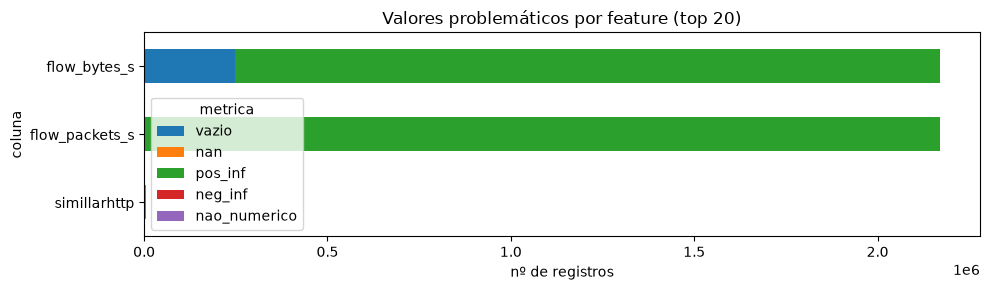

In [16]:
# Gráfico: top features por % de valores problemáticos
top = qual_global[qual_global.problemas_total > 0].sort_values("pct_problemas", ascending=False).head(20)
if len(top):
    ax = top[["vazio", "nan", "pos_inf", "neg_inf", "nao_numerico"]].plot(
        kind="barh", stacked=True, figsize=(10, max(3, 0.35 * len(top))), logx=False)
    ax.invert_yaxis(); ax.set_xlabel("nº de registros"); ax.set_title("Valores problemáticos por feature (top 20)")
    salvar_fig("05_valores_problematicos")
else:
    print("Sem valores problemáticos para plotar.")

## 6. Análise 6 — Duplicatas

`unnamed_0` (índice de linha) e `flow_id` tornam quase qualquer linha única; por isso a duplicação é medida
em **dois níveis**, do mais estrito ao mais relevante para ML:

* **B – Sem `unnamed_0`** (o índice de linha torna toda linha única, então a duplicata "completa" é sempre 0 e foi omitida):: mesma observação de rede (IPs, portas, timestamp, features, label).
* **C – Só features + label**: fluxos estatisticamente idênticos, independentemente de IP/porta/horário.
  É a duplicação que causa *vazamento* entre treino e teste.

Também medimos **conflito de rótulo**: mesmas features, labels diferentes.
A linha `TOTAL` considera duplicatas **entre tabelas** (o mesmo fluxo em mais de um arquivo).

**Como é medido sem estourar a memória do servidor:** agrupar dezenas de milhões de linhas por hash exige GBs na memória.
Aqui cada linha é reduzida **uma vez** a um hash compacto, gravado numa tabela auxiliar pequena (`eda_tmp_hash_<tabela>`,
só 4 colunas numéricas, apagada ao final). A contagem é feita em *faixas* do hash (`LINHAS_POR_BUCKET` grupos por consulta),
então a memória por consulta é pequena e constante. Isso também permite medir duplicatas **entre tabelas** (TOTAL).
Sem permissão para criar tabelas, o notebook volta para leitura direta (por faixas), sem o TOTAL entre tabelas.

In [17]:
import csv

cols_B = [c for c in COLUNAS_COMUNS if c != "unnamed_0"]
cols_C = FEATURES + [COL_LABEL]
_ID_SEM_INDICE = [c for c in COLUNAS_ID if c != "unnamed_0"]
_N_TAB = registros_tabela.set_index("tabela")["registros"]
_aux_ok = None                      # None = ainda não testado; False = sem permissão
_bk_path = OUT / "06_dup_buckets.csv"   # progresso fino (por faixa) para retomar dentro de uma unidade grande
_bk = {}
if _bk_path.exists() and not REFAZER:
    for r in csv.DictReader(open(_bk_path, encoding="utf-8")):
        _bk[(r["escopo"], r["nivel"], r["via"], int(r["k"]), int(r["K"]))] = (int(r["linhas"]), int(r["red"]))


def _salva_bk(chave, valor):
    _bk[chave] = valor
    novo = not _bk_path.exists()
    with open(_bk_path, "a", newline="", encoding="utf-8") as f:
        w = csv.writer(f)
        if novo:
            w.writerow(["escopo", "nivel", "via", "k", "K", "linhas", "red"])
        w.writerow([*chave, *valor])


def _aux(t):
    return PREFIXO_AUX + t


def _escapa(l):
    return l.replace("\\", "\\\\").replace("'", "\\'")


def _garantir_aux(t, rodada):
    # Cria eda_tmp_hash_<t> (f1, f2 = hashes das features; b3 = hash dos identificadores+label; lab = id da classe).
    aux, n = _aux(t), int(_N_TAB[t])
    try:
        r = _executar(f"SELECT toString(count()) AS n FROM `{aux}`")
        if int(r["n"][0]) == n:
            return                                   # já pronta e completa
    except Exception as e:
        if erro_memoria(e):
            raise                                    # rede/memória: tenta de novo na próxima rodada
    feats = ", ".join(f"`{c}`" for c in FEATURES)
    ids = ", ".join([f"`{c}`" for c in _ID_SEM_INDICE] + [f"`{COL_LABEL}`"])
    labs = "[" + ", ".join(f"'{_escapa(l)}'" for l in distribuicao["label_norm"]) + "]"
    lab_ids = "[" + ", ".join(str(i) for i in range(len(distribuicao))) + "]"
    print(f"  gravando hashes de {t} ({n:,} linhas) em {aux} ...")
    _executar(f"DROP TABLE IF EXISTS `{aux}`")
    _executar(f"CREATE TABLE `{aux}` (f1 UInt64, f2 UInt64, b3 UInt64, lab UInt8) ENGINE = MergeTree ORDER BY f1")
    _executar(f"INSERT INTO `{aux}` SELECT sipHash64({feats}), cityHash64({feats}), cityHash64({ids}), "
              f"toUInt8(transform(trimBoth(`{COL_LABEL}`), {labs}, {lab_ids}, 255)) FROM `{t}`\n{sett(rodada)}")


def _preparar_aux(tabs, rodada):
    global _aux_ok
    if not USAR_TABELAS_AUXILIARES or _aux_ok is False:
        return False
    try:
        for t in tabs:
            _garantir_aux(t, rodada)
        _aux_ok = True
        return True
    except Exception as e:
        if erro_memoria(e):
            raise
        m = str(e)
        if "ACCESS_DENIED" in m or "rivileges" in m or "readonly" in m.lower():
            _aux_ok = False
            print("  ⚠ sem permissão para criar tabelas auxiliares; usando leitura direta (sem duplicatas ENTRE tabelas)")
            return False
        raise


def _faixa(k, K):
    lo, hi = k * 2 ** 64 // K, (k + 1) * 2 ** 64 // K
    return f"f1 >= {lo}" + ("" if k == K - 1 else f" AND f1 < {hi}")


def _uniao(tabs, cond):
    return " UNION ALL ".join(f"SELECT f1, f2, b3, lab FROM `{_aux(t)}` WHERE {cond}" for t in tabs)


def _dup_aux(escopo, tabs, nivel, rodada):
    K = max(1, -(-int(sum(_N_TAB[t] for t in tabs)) // LINHAS_POR_BUCKET))
    chave = {"B": "f1, f2, b3", "C": "f1, f2, lab"}[nivel]
    reg = red = 0
    for k in range(K):
        ck = (escopo, nivel, "aux", k, K)
        if ck not in _bk:
            r = num(ch(f"SELECT toString(sum(n)) AS linhas, toString(sum(n - 1)) AS red "
                       f"FROM (SELECT count() AS n FROM ({_uniao(tabs, _faixa(k, K))}) GROUP BY {chave})\n{sett(rodada)}"))
            _salva_bk(ck, (int(r.linhas[0]), int(r.red[0])))
        reg += _bk[ck][0]
        red += _bk[ck][1]
    return reg, red


def _conflito_aux(rodada):
    K = max(1, -(-int(_N_TAB.sum()) // LINHAS_POR_BUCKET))
    grupos = regs = 0
    for k in range(K):
        ck = ("TOTAL", "conflito", "aux", k, K)
        if ck not in _bk:
            r = num(ch(f"SELECT toString(count()) AS g, toString(sum(n)) AS r FROM ("
                       f"SELECT count() AS n FROM ({_uniao(TABELAS, _faixa(k, K))}) "
                       f"GROUP BY f1, f2 HAVING uniqExact(lab) > 1)\n{sett(rodada)}"))
            _salva_bk(ck, (int(r.g[0]), int(r.r[0])))
        grupos += _bk[ck][0]
        regs += _bk[ck][1]
    return grupos, regs


def _dup_direto(t, nivel, rodada):
    # Sem tabela auxiliar: lê a tabela K vezes, cada vez só com as linhas de uma faixa do hash.
    cols = cols_B if nivel == "B" else cols_C
    K = max(1, -(-int(_N_TAB[t]) // LINHAS_POR_BUCKET))
    h = "sipHash128(" + ", ".join(f"`{c}`" for c in cols) + ")"
    reg = red = 0
    for k in range(K):
        ck = (t, nivel, "direto", k, K)
        if ck not in _bk:
            filtro = f"WHERE cityHash64(h) % {K} = {k}" if K > 1 else ""
            r = num(ch(f"SELECT toString(sum(n)) AS linhas, toString(sum(n - 1)) AS red FROM ("
                       f"SELECT count() AS n FROM (SELECT {h} AS h FROM `{t}`) {filtro} GROUP BY h)\n{sett(rodada)}"))
            _salva_bk(ck, (int(r.linhas[0]), int(r.red[0])))
        reg += _bk[ck][0]
        red += _bk[ck][1]
    return reg, red


def _medir_duplicatas(faltam, rodada):
    partes = []
    for t, nivel in faltam:
        try:
            if nivel == "conflito":
                if not _preparar_aux(TABELAS, rodada):
                    raise RuntimeError("Medir TOTAL entre tabelas exige tabelas auxiliares (permissão CREATE). "
                                       "Defina TOTAL_ENTRE_TABELAS = False na célula de funções auxiliares e rode de novo.")
                g, rg = _conflito_aux(rodada)
                partes.append(pd.DataFrame({"tabela": [t], "nivel": [nivel], "registros": [rg], "valor": [g]}))
                continue
            tabs = TABELAS if t == "TOTAL" else [t]
            if _preparar_aux(tabs, rodada):
                n, red = _dup_aux(t, tabs, nivel, rodada)
            elif t != "TOTAL":
                n, red = _dup_direto(t, nivel, rodada)
            else:
                raise RuntimeError("Medir TOTAL entre tabelas exige tabelas auxiliares (permissão CREATE). "
                                   "Defina TOTAL_ENTRE_TABELAS = False na célula de funções auxiliares e rode de novo.")
            partes.append(pd.DataFrame({"tabela": [t], "nivel": [nivel], "registros": [n], "valor": [red]}))
        except Exception as e:
            if not erro_memoria(e):
                raise
            print(f"  ✖ duplicatas {t}/{nivel}: instabilidade/memória; fica para a próxima rodada (faixas prontas ficam salvas)")
    return pd.concat(partes, ignore_index=True) if partes else None


esperado_dup = [(t, n) for t in TABELAS for n in ("B", "C")]
if TOTAL_ENTRE_TABELAS:
    esperado_dup += [("TOTAL", "B"), ("TOTAL", "C"), ("TOTAL", "conflito")]
dup_long = completar("06_duplicatas_long", esperado_dup, _medir_duplicatas,
                     lambda d: set(zip(d["tabela"], d["nivel"])), lote=1)

if not TOTAL_ENTRE_TABELAS:     # TOTAL = soma das tabelas (não inclui duplicatas entre tabelas; conflito não medido)
    _soma = (dup_long[dup_long.nivel.isin(["B", "C"])].groupby("nivel")[["registros", "valor"]].sum().reset_index())
    _soma["tabela"] = "TOTAL"
    dup_long = pd.concat([dup_long[dup_long.tabela != "TOTAL"], _soma], ignore_index=True)

if LIMPAR_AUX_AO_FINAL and (_aux_ok or _aux_ok is None):
    for _t in TABELAS:
        try:
            _executar(f"DROP TABLE IF EXISTS `{_aux(_t)}`")
        except Exception:
            pass

_b = dup_long[dup_long.nivel == "B"].set_index("tabela")
_c = dup_long[dup_long.nivel == "C"].set_index("tabela")
_f = dup_long[dup_long.nivel == "conflito"].set_index("tabela")
duplicatas = pd.DataFrame({"registros": _b["registros"], "dup_B_sem_indice": _b["valor"],
                           "dup_C_features_label": _c["valor"]})
duplicatas["conflito_grupos"] = _f["valor"]
duplicatas["conflito_registros"] = _f["registros"]
duplicatas = duplicatas.reindex(TABELAS + ["TOTAL"]).rename_axis("tabela").reset_index()
for c in ["dup_B_sem_indice", "dup_C_features_label"]:
    duplicatas["pct_" + c.split("_")[1]] = duplicatas[c] / duplicatas["registros"] * 100
display(duplicatas)

t = duplicatas[duplicatas.tabela == "TOTAL"].iloc[0]
print(f"\nDuplicadas (features+label, entre todas as tabelas): {t.dup_C_features_label:,.0f} de {t.registros:,.0f} "
      f"= {t.dup_C_features_label / t.registros:.2%}")
print(f"Registros com features idênticas e labels conflitantes: {t.conflito_registros:,.0f}")

[cache] 06_duplicatas_long: completo (36 unidades)


,tabela,registros,dup_B_sem_indice,dup_C_features_label,conflito_grupos,conflito_registros,pct_B,pct_C
0,data2_ldap,2113234,0,2089294,NaN,NaN,0.0000,98.8671
1,data2_mssql,5775786,0,5501042,NaN,NaN,0.0000,95.2432
2,data2_netbios,3455899,0,3444572,NaN,NaN,0.0000,99.6722
3,data2_portmap,191694,0,185603,NaN,NaN,0.0000,96.8225
4,data2_syn,4320541,482799,3840360,NaN,NaN,11.1745,88.8861
5,data2_udp,3782206,0,2484521,NaN,NaN,0.0000,65.6897
6,data2_udplag,725165,0,585344,NaN,NaN,0.0000,80.7187
7,data_drdos_dns,5074413,0,4958078,NaN,NaN,0.0000,97.7074
8,data_drdos_ldap,2181542,0,2150031,NaN,NaN,0.0000,98.5556
9,data_drdos_mssql,4524498,0,4315609,NaN,NaN,0.0000,95.3832



Duplicadas (features+label, entre todas as tabelas): 59,927,555 de 89,309,557 = 67.10%
Registros com features idênticas e labels conflitantes: nan


## 7. Análises 7 e 8 — Estatísticas descritivas, constantes e baixa variabilidade

Uma única varredura por bloco de features calcula, **só sobre valores finitos**, min, max, média, desvio-padrão,
Q1/mediana/Q3 e nº de valores distintos — para o dataset inteiro e, com `ROLLUP`, também separado por
`benigno`/`ataque` (linha `total` = dataset todo).

> Quartis usam `quantileTDigest` (aproximação por t-digest, erro típico < 1%), adequada para dezenas de milhões de linhas.
> `nunique` usa `uniq` (estimativa HyperLogLog; exata para valores 1 ou 2).

In [18]:
def _consulta_stats(grupo, rodada):
    ex = []
    for c in grupo:
        x = f"toFloat64OrNull(`{c}`)"
        f = f"ifNull(isFinite({x}), 0)"
        ex += [
            f"toString(countIf({f})) AS `{c}__validos`",
            f"toString(minIf({x}, {f})) AS `{c}__min`",
            f"toString(maxIf({x}, {f})) AS `{c}__max`",
            f"toString(avgIf({x}, {f})) AS `{c}__media`",
            f"toString(stddevPopIf({x}, {f})) AS `{c}__desvio`",
            f"toString(quantilesTDigestIf(0.25, 0.5, 0.75)({x}, {f})[1]) AS `{c}__q1`",
            f"toString(quantilesTDigestIf(0.25, 0.5, 0.75)({x}, {f})[2]) AS `{c}__mediana`",
            f"toString(quantilesTDigestIf(0.25, 0.5, 0.75)({x}, {f})[3]) AS `{c}__q3`",
            f"toString(uniq(`{c}`)) AS `{c}__nunique`",
        ]
    wide = ch(f'''
        SELECT {ALVO_SQL} AS grupo, {", ".join(ex)}
        FROM {src(grupo + [COL_LABEL])}
        GROUP BY grupo WITH ROLLUP
        {sett(rodada)}
    ''')
    wide["grupo"] = wide["grupo"].replace("", "total")
    long = wide.melt(id_vars=["grupo"], var_name="chave", value_name="valor")
    long[["coluna", "metrica"]] = long["chave"].str.rsplit("__", n=1, expand=True)
    long["valor"] = pd.to_numeric(long["valor"], errors="coerce")
    return long.drop(columns="chave")


def _medir_stats(faltam, rodada):
    partes = []
    for grupo in blocos(faltam, COLS_POR_CONSULTA if rodada == 1 else 1):
        partes.extend(com_divisao(grupo, lambda g: _consulta_stats(g, rodada), rotulo="dataset inteiro"))
    return pd.concat(partes, ignore_index=True) if partes else None


stats_long = completar("07_estatisticas_long", FEATURES, _medir_stats, lambda d: set(d["coluna"]))
stats = stats_long.pivot_table(index=["coluna", "grupo"], columns="metrica", values="valor", aggfunc="first").reset_index()

stats_total = stats[stats.grupo == "total"].set_index("coluna").reindex(FEATURES)
# onde não há valor finito, min/max/média não têm significado
sem_valido = stats_total["validos"] == 0
stats_total.loc[sem_valido, ["min", "max", "media", "desvio", "q1", "mediana", "q3"]] = np.nan

colunas_stats = ["validos", "min", "q1", "mediana", "media", "q3", "max", "desvio", "nunique"]
print("Estatísticas descritivas — dataset inteiro (valores finitos):")
display(stats_total[colunas_stats])

[calculando] 07_estatisticas_long: 80 unidades
[07_estatisticas_long] rodada 1/8: 80 unidade(s) a medir
  ⚠ conexão instável (Exception); nova tentativa em 5s...
  ⚠ conexão instável (Exception); nova tentativa em 15s...
  ⚠ conexão instável (Exception); nova tentativa em 5s...
  ⚠ conexão instável (Exception); nova tentativa em 15s...
  ⚠ conexão instável (Exception); nova tentativa em 45s...
  ⚠ conexão instável (Exception); nova tentativa em 90s...
  ⚠ memória insuficiente com 2 colunas (dataset inteiro); dividindo (1 + 1)
  ⚠ conexão instável (Exception); nova tentativa em 5s...
  ⚠ conexão instável (Exception); nova tentativa em 15s...
  ⚠ conexão instável (Exception); nova tentativa em 45s...
  ⚠ conexão instável (Exception); nova tentativa em 90s...
  ✖ fwd_packet_length_mean (dataset inteiro): sem memória; fica para a próxima rodada
  ⚠ conexão instável (Exception); nova tentativa em 5s...
  ⚠ conexão instável (Exception); nova tentativa em 15s...
  ⚠ conexão instável (Exceptio

metrica,validos,min,q1,mediana,media,q3,max,desvio,nunique
coluna,,,,,,,,,
protocol,"70,427,637.0000",0.0000,17.0000,17.0000,15.9015,17.0000,17.0000,3.2989,3.0000
flow_duration,"70,427,637.0000",0.0000,1.0000,1.0000,"1,189,558.2628",402.8513,"120,000,000.0000","6,487,063.2000","1,546,216.0000"
total_fwd_packets,"70,427,637.0000",1.0000,2.0000,2.0000,4.3605,2.4858,"100,148.0000",220.2497,853.0000
total_backward_packets,"70,427,637.0000",0.0000,0.0000,0.0000,0.0986,0.0000,"31,700.0000",4.5117,464.0000
total_length_of_fwd_packets,"70,427,637.0000",0.0000,766.0026,"1,033.4584","1,976.3619","2,377.2517","15,266,416.0000","5,701.6965","6,880.0000"
total_length_of_bwd_packets,"70,427,637.0000",0.0000,0.0000,0.0000,11.3792,0.0000,"58,429,504.0000","8,396.1102","6,359.0000"
fwd_packet_length_max,"70,427,637.0000",0.0000,374.9990,516.0000,603.1322,545.3113,"32,120.0000",459.9625,"2,593.0000"
fwd_packet_length_min,"70,427,637.0000",0.0000,328.2068,516.0000,597.4749,545.0546,"2,131.0000",462.9232,"1,494.0000"
fwd_packet_length_mean,"70,427,637.0000",0.0000,349.5000,516.0000,600.5865,546.2902,"3,015.2905",461.0294,"13,552.0000"


In [19]:
# Tipo inferido (conteúdo) para fechar a Análise 3
inferido = pd.DataFrame({"coluna": FEATURES})
nao_num = qual_global["nao_numerico"].reindex(FEATURES).values
validos = stats_total["validos"].values
inferido["tipo_inferido"] = np.where(nao_num > 0, "texto/misto", np.where(validos > 0, "numérico", "sem valor válido"))
# inteiro x decimal: inteiro se min, max, q1, mediana, q3 forem inteiros
ints = ((stats_total[["min", "max", "q1", "mediana", "q3"]] % 1 == 0).all(axis=1)).reindex(FEATURES).values
inferido.loc[(inferido.tipo_inferido == "numérico") & ints, "tipo_inferido"] = "numérico (inteiro)"
inferido.loc[inferido.tipo_inferido == "numérico", "tipo_inferido"] = "numérico (decimal)"

tipos_final = tipos_declarados.merge(inferido, on="coluna", how="left")
print(inferido["tipo_inferido"].value_counts().to_string())
nao_feature = tipos_final[(tipos_final.papel == "feature") & (tipos_final.tipo_inferido.isin(["texto/misto", "sem valor válido"]))]
print("\nFeatures que NÃO se comportam como numéricas (candidatas a não serem usadas):")
display(nao_feature if len(nao_feature) else pd.DataFrame({"resultado": ["nenhuma"]}))
tipos_final.to_csv(OUT / "03_tipos_colunas.csv", index=False)

tipo_inferido
numérico (inteiro)    46
numérico (decimal)    33
texto/misto            1

Features que NÃO se comportam como numéricas (candidatas a não serem usadas):


,coluna,tipo,papel,tipo_inferido
85,simillarhttp,String,feature,texto/misto


In [20]:
# Análise 7: constantes e baixa variabilidade
var = stats_total[["validos", "min", "max", "media", "desvio", "nunique"]].copy()
var["variancia"] = var["desvio"] ** 2
var["coef_variacao"] = var["desvio"] / var["media"].abs().replace(0, np.nan)

var["constante"] = ((var["min"] == var["max"]) & (var["validos"] > 0)) | (var["nunique"] <= 1)
var["sem_valor_valido"] = var["validos"] == 0
var["binaria"] = (~var["constante"]) & (var["nunique"] == 2)          # flag 0/1: legítima, só 2 valores
var["quase_constante"] = (~var["constante"]) & (~var["binaria"]) & (var["coef_variacao"].abs() < 1e-3)

print(f"Constantes (min = max / nunique = 1): {int(var.constante.sum())}")
display(var[var.constante][["min", "max", "nunique"]] if var.constante.any() else "nenhuma")
print(f"\nSem nenhum valor válido: {int(var.sem_valor_valido.sum())}", list(var.index[var.sem_valor_valido]))
print(f"\nBinárias (exatamente 2 valores distintos — normalmente flags): {int(var.binaria.sum())}")
display(var[var.binaria][["min", "max", "nunique"]] if var.binaria.any() else "nenhuma")
print(f"\nQuase constantes (coef. de variação < 0,001 com ≥ 3 valores distintos): {int(var.quase_constante.sum())}")
display(var[var.quase_constante][["min", "max", "nunique", "variancia", "coef_variacao"]]
        if var.quase_constante.any() else "nenhuma")
var.to_csv(OUT / "07_variabilidade.csv")

Constantes (min = max / nunique = 1): 13


metrica,min,max,nunique
coluna,,,
bwd_psh_flags,0.0000,0.0000,1.0000
fwd_urg_flags,0.0000,0.0000,1.0000
bwd_urg_flags,0.0000,0.0000,1.0000
fin_flag_count,0.0000,0.0000,1.0000
psh_flag_count,0.0000,0.0000,1.0000
ece_flag_count,0.0000,0.0000,1.0000
fwd_avg_bytes_bulk,0.0000,0.0000,1.0000
fwd_avg_packets_bulk,0.0000,0.0000,1.0000
fwd_avg_bulk_rate,0.0000,0.0000,1.0000



Sem nenhum valor válido: 0 []

Binárias (exatamente 2 valores distintos — normalmente flags): 7


metrica,min,max,nunique
coluna,,,
fwd_psh_flags,0.0000,1.0000,2.0000
syn_flag_count,0.0000,1.0000,2.0000
rst_flag_count,0.0000,1.0000,2.0000
ack_flag_count,0.0000,1.0000,2.0000
urg_flag_count,0.0000,1.0000,2.0000
cwe_flag_count,0.0000,1.0000,2.0000
inbound,0.0000,1.0000,2.0000



Quase constantes (coef. de variação < 0,001 com ≥ 3 valores distintos): 0


'nenhuma'

## 8. Análise 9 — Outliers (apenas identificação)

Regra de Tukey com os quartis do dataset inteiro: valor fora de `[Q1 − 1,5·IQR, Q3 + 1,5·IQR]` é *outlier*, e fora de
`[Q1 − 3·IQR, Q3 + 3·IQR]` é *outlier extremo*. Features com IQR = 0 são ignoradas (a regra não é informativa).

O ponto central: **se os outliers se concentram na classe ataque, eles são o sinal, não o ruído** — por isso não são removidos aqui.

In [21]:
lim = stats_total[["q1", "q3", "validos"]].copy()
lim["iqr"] = lim["q3"] - lim["q1"]
usaveis = lim[(lim["validos"] > 0) & (lim["iqr"] > 0)].index.tolist()
g = lambda v: format(float(v), ".17g")


def _consulta_outliers(grupo, rodada):
    ex = []
    for c in grupo:
        x = f"toFloat64OrNull(`{c}`)"
        f = f"ifNull(isFinite({x}), 0)"
        q1, q3, iqr = lim.loc[c, "q1"], lim.loc[c, "q3"], lim.loc[c, "iqr"]
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        lo3, hi3 = q1 - 3 * iqr, q3 + 3 * iqr
        ex += [
            f"toString(countIf({f} AND ({x} < {g(lo)} OR {x} > {g(hi)}))) AS `{c}__outlier`",
            f"toString(countIf({f} AND ({x} < {g(lo3)} OR {x} > {g(hi3)}))) AS `{c}__extremo`",
            f"toString(countIf({f})) AS `{c}__validos`",
        ]
    wide = ch(f'''
        SELECT {ALVO_SQL} AS grupo, {", ".join(ex)}
        FROM {src(grupo + [COL_LABEL])}
        GROUP BY grupo WITH ROLLUP
        {sett(rodada)}
    ''')
    wide["grupo"] = wide["grupo"].replace("", "total")
    long = wide.melt(id_vars=["grupo"], var_name="chave", value_name="valor")
    long[["coluna", "metrica"]] = long["chave"].str.rsplit("__", n=1, expand=True)
    long["valor"] = pd.to_numeric(long["valor"], errors="coerce")
    return long.drop(columns="chave")


def _medir_outliers(faltam, rodada):
    partes = []
    for grupo in blocos(faltam, COLS_POR_CONSULTA if rodada == 1 else 1):
        partes.extend(com_divisao(grupo, lambda g_: _consulta_outliers(g_, rodada), rotulo="dataset inteiro"))
    return pd.concat(partes, ignore_index=True) if partes else None


out_long = completar("09_outliers_long", usaveis, _medir_outliers, lambda d: set(d["coluna"]))
out_w = out_long.pivot_table(index=["coluna", "grupo"], columns="metrica", values="valor", aggfunc="first").reset_index()
out_w["pct_outlier"] = out_w["outlier"] / out_w["validos"] * 100
out_w["pct_extremo"] = out_w["extremo"] / out_w["validos"] * 100

resumo_out = out_w.pivot(index="coluna", columns="grupo", values=["pct_outlier", "pct_extremo"])
resumo_out.columns = [f"{a}_{b}" for a, b in resumo_out.columns]
resumo_out = resumo_out.sort_values("pct_outlier_total", ascending=False)
print("% de outliers por feature (total / benigno / ataque):")
display(resumo_out.head(30))
print(f"\nFeatures ignoradas por IQR = 0: {len(FEATURES) - resumo_out.shape[0]}")

[calculando] 09_outliers_long: 27 unidades
[09_outliers_long] rodada 1/8: 27 unidade(s) a medir
  ⚠ conexão instável (Exception); nova tentativa em 5s...
  10/27 (37%) | decorrido 0min39s | restante ~1min06s
  ⚠ conexão instável (Exception); nova tentativa em 5s...
  ⚠ conexão instável (Exception); nova tentativa em 15s...
  ⚠ conexão instável (Exception); nova tentativa em 45s...
  [  87.4s] 3 linha(s) x 13 coluna(s)
  20/27 (74%) | decorrido 2min20s | restante ~0min49s
  ⚠ conexão instável (Exception); nova tentativa em 5s...
  ⚠ conexão instável (Exception); nova tentativa em 15s...
  ⚠ conexão instável (Exception); nova tentativa em 45s...
  ⚠ conexão instável (Exception); nova tentativa em 90s...
  ⚠ memória insuficiente com 4 colunas (dataset inteiro); dividindo (2 + 2)
  ⚠ conexão instável (Exception); nova tentativa em 5s...
  ⚠ conexão instável (Exception); nova tentativa em 15s...
  27/27 (100%) | decorrido 6min01s | restante ~0min00s
✔ [09_outliers_long] completo: 27 unidade

,pct_outlier_ataque,pct_outlier_benigno,pct_outlier_total,pct_extremo_ataque,pct_extremo_benigno,pct_extremo_total
coluna,,,,,,
fwd_packet_length_max,31.1245,88.9570,31.2180,20.2756,3.4807,20.2485
max_packet_length,31.1089,89.2118,31.2028,20.2736,11.2714,20.2590
avg_fwd_segment_size,30.9286,85.1671,31.0163,20.1983,0.1168,20.1658
fwd_packet_length_mean,30.9182,85.0994,31.0058,20.1975,0.1142,20.1651
packet_length_mean,30.8946,58.1307,30.9387,20.1946,0.2144,20.1623
act_data_pkt_fwd,27.4066,57.9646,27.4559,27.4066,57.9646,27.4559
subflow_fwd_packets,24.8019,44.8352,24.8342,8.2001,21.4042,8.2215
total_fwd_packets,24.8019,44.8352,24.8342,24.7879,28.0283,24.7931
fwd_iat_total,24.1367,26.6472,24.1408,23.9301,25.6747,23.9330



Features ignoradas por IQR = 0: 53


## 9. Amostra estratificada para o Pandas

Até `AMOSTRA_POR_CLASSE` linhas aleatórias **por label** (classes raras entram inteiras).
Valores `inf`/`-inf` viram `NaN` na amostra (a contagem real já foi feita no dataset inteiro).

**Método (uma passada por tabela):** cada tabela é lida **uma vez**, e cada linha é sorteada com a taxa da sua classe
(`min(1, AMOSTRA_POR_CLASSE / registros_da_classe)`). O resultado equivale a "até `AMOSTRA_POR_CLASSE` linhas aleatórias por label",
com classes raras inteiras, sem reler o dataset uma vez por label.

In [22]:
def _medir_amostra(faltam, rodada):
    # Taxa de sorteio por classe (em milionésimos). transform() mapeia label -> limiar numa só busca por linha.
    cols = ", ".join(f"`{c}`" for c in FEATURES)
    labs = distribuicao["label_norm"].tolist()
    lista_labs = "[" + ", ".join("'" + l.replace("\\", "\\\\").replace("'", "\\'") + "'" for l in labs) + "]"
    limiares = [max(1, int(min(1.0, AMOSTRA_POR_CLASSE / int(n)) * 1_000_000)) for n in distribuicao["registros"]]
    lista_lim = "[" + ", ".join(str(v) for v in limiares) + "]"
    partes = []
    for t in faltam:
        q = f"""
        SELECT trimBoth(`{COL_LABEL}`) AS classe, '{t}' AS tabela, {cols}
        FROM `{t}`
        WHERE rand() % 1000000 < transform(trimBoth(`{COL_LABEL}`), {lista_labs}, {lista_lim}, 0)
        {sett(rodada)}
        """
        print(f"amostrando {t} (1 passada)")
        try:
            partes.append(ch(q).rename(columns={"classe": "label"}))
        except Exception as e:
            if not erro_memoria(e):
                raise
            print(f"  ✖ {t}: sem memória; fica para a próxima rodada")
    return pd.concat(partes, ignore_index=True) if partes else None


amostra = completar("10_amostra_v2", TABELAS, _medir_amostra, lambda d: set(d["tabela"]), ext="csv.gz", lote=1)
amostra[FEATURES] = amostra[FEATURES].apply(pd.to_numeric, errors="coerce")
amostra[FEATURES] = amostra[FEATURES].replace([np.inf, -np.inf], np.nan)
amostra["grupo"] = np.where(amostra["label"].str.upper() == "BENIGN", "benigno", "ataque")
amostra["alvo"] = (amostra["grupo"] == "ataque").astype(int)
print(f"Amostra: {len(amostra):,} linhas | {amostra['label'].nunique()} classes")
display(amostra["label"].value_counts().to_frame("linhas_na_amostra"))

[calculando] 10_amostra_v2: 18 unidades
[10_amostra_v2] rodada 1/8: 18 unidade(s) a medir
amostrando data2_ldap (1 passada)
  1/18 (6%) | decorrido 0min02s | restante ~0min34s
amostrando data2_mssql (1 passada)
  ⚠ conexão instável (Exception); nova tentativa em 5s...
  ⚠ conexão instável (Exception); nova tentativa em 15s...
  2/18 (11%) | decorrido 0min29s | restante ~3min54s
amostrando data2_netbios (1 passada)
amostrando data2_portmap (1 passada)
amostrando data2_syn (1 passada)
  ⚠ conexão instável (Exception); nova tentativa em 5s...
  5/18 (28%) | decorrido 0min51s | restante ~2min14s
amostrando data2_udp (1 passada)
amostrando data2_udplag (1 passada)
amostrando data_drdos_dns (1 passada)
  ⚠ conexão instável (Exception); nova tentativa em 5s...
  ⚠ conexão instável (Exception); nova tentativa em 15s...
  8/18 (44%) | decorrido 1min36s | restante ~2min00s
amostrando data_drdos_ldap (1 passada)
amostrando data_drdos_mssql (1 passada)
  ⚠ conexão instável (Exception); nova tentat

,linhas_na_amostra
label,
Syn,10235
DrDoS_MSSQL,10178
BENIGN,10166
DrDoS_LDAP,10075
UDP,10071
NetBIOS,10062
DrDoS_SNMP,10053
Portmap,10049
TFTP,10037


## 10. Análise 10 — Correlação (amostra)

Correlação de Pearson entre as features que variam (constantes ficam de fora, pois geram NaN).
Objetivo: **listar pares com |r| > 0,95** como candidatos à remoção na seleção de atributos.

In [23]:
usar = [c for c in FEATURES if not var.loc[c, "constante"] and not var.loc[c, "sem_valor_valido"]
        and amostra[c].nunique(dropna=True) > 1]
corr = amostra[usar].corr(method="pearson")

# pares altamente correlacionados
tri = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pares = (tri.stack().rename("r").reset_index().rename(columns={"level_0": "feature_a", "level_1": "feature_b"}))
pares["abs_r"] = pares["r"].abs()
pares_altos = pares[pares.abs_r > LIMIAR_CORR].sort_values("abs_r", ascending=False).reset_index(drop=True)
pares_altos.to_csv(OUT / "10_pares_correlacionados.csv", index=False)

print(f"{len(usar)} features analisadas | {len(pares_altos)} pares com |r| > {LIMIAR_CORR}")
display(pares_altos.head(50))

# Features "redundantes": para cada par, a segunda feature é candidata à remoção
candidatas = sorted(set(pares_altos["feature_b"]))
print(f"\nCandidatas a remoção por redundância (|r| > {LIMIAR_CORR}): {len(candidatas)}")
print(candidatas)

67 features analisadas | 47 pares com |r| > 0.95


,feature_a,feature_b,r,abs_r
0,total_fwd_packets,subflow_fwd_packets,1.0000,1.0000
1,total_length_of_fwd_packets,subflow_fwd_bytes,1.0000,1.0000
2,total_backward_packets,subflow_bwd_packets,1.0000,1.0000
3,total_length_of_bwd_packets,subflow_bwd_bytes,1.0000,1.0000
4,fwd_psh_flags,rst_flag_count,1.0000,1.0000
5,bwd_packet_length_mean,avg_bwd_segment_size,1.0000,1.0000
6,fwd_packet_length_mean,avg_fwd_segment_size,1.0000,1.0000
7,fwd_header_length,fwd_header_length_1,1.0000,1.0000
8,flow_packets_s,fwd_packets_s,0.9997,0.9997
9,fwd_packet_length_min,min_packet_length,0.9997,0.9997



Candidatas a remoção por redundância (|r| > 0.95): 25
['act_data_pkt_fwd', 'average_packet_size', 'avg_bwd_segment_size', 'avg_fwd_segment_size', 'bwd_packet_length_std', 'fwd_header_length_1', 'fwd_iat_max', 'fwd_iat_mean', 'fwd_iat_min', 'fwd_iat_std', 'fwd_iat_total', 'fwd_packet_length_mean', 'fwd_packet_length_min', 'fwd_packets_s', 'idle_max', 'idle_mean', 'idle_min', 'max_packet_length', 'min_packet_length', 'packet_length_mean', 'rst_flag_count', 'subflow_bwd_bytes', 'subflow_bwd_packets', 'subflow_fwd_bytes', 'subflow_fwd_packets']


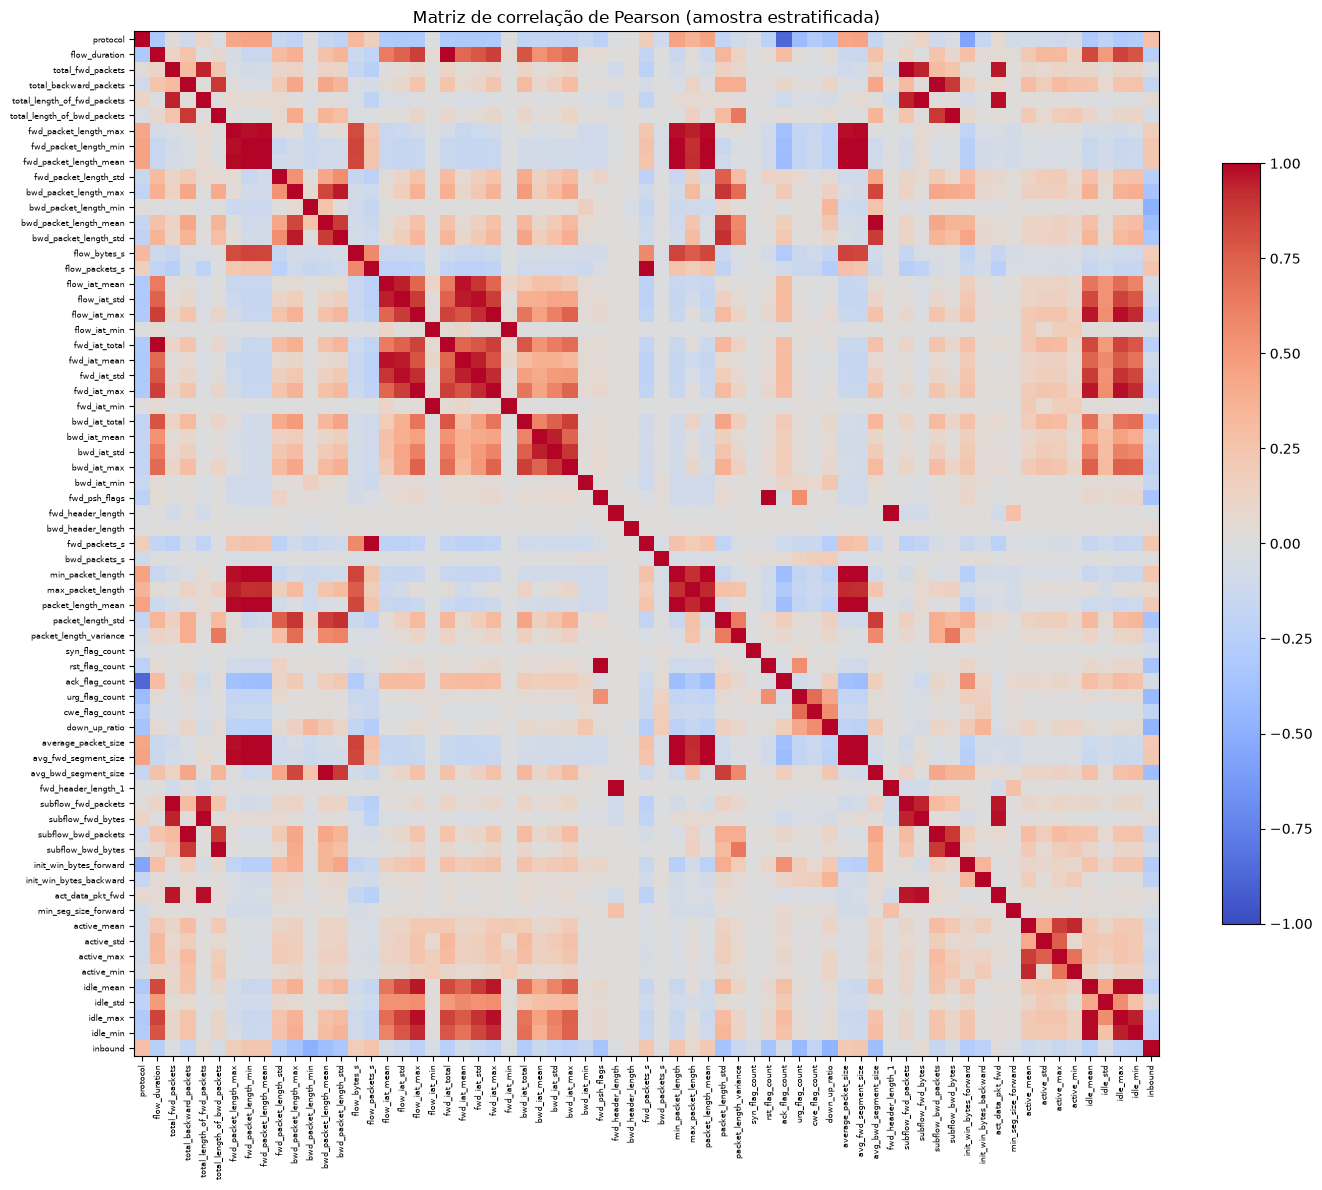

In [24]:
fig, ax = plt.subplots(figsize=(14, 12))
im = ax.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(usar))); ax.set_xticklabels(usar, rotation=90, fontsize=6)
ax.set_yticks(range(len(usar))); ax.set_yticklabels(usar, fontsize=6)
plt.colorbar(im, fraction=0.03)
ax.set_title("Matriz de correlação de Pearson (amostra estratificada)")
salvar_fig("10_matriz_correlacao")

## 11. Análises 11 e 14 — Distribuições e relação Feature × Classe

**Pergunta:** os ataques apresentam comportamento estatístico diferente do tráfego benigno?

1. Tabela com **medianas e médias (dataset inteiro)** de cada feature por grupo.
2. **AUC univariada** (amostra): probabilidade de uma feature, sozinha, ordenar um ataque acima de um benigno
   (0,5 = não separa; 0 ou 1 = separa perfeitamente).
3. Histogramas e boxplots das features-chave, benigno vs ataque.

In [25]:
# 1) medianas/médias por grupo no dataset inteiro
cmp_ = stats[stats.grupo.isin(["benigno", "ataque"])].pivot(index="coluna", columns="grupo", values=["mediana", "media"])
cmp_.columns = [f"{a}_{b}" for a, b in cmp_.columns]
cmp_ = cmp_.reindex(FEATURES)

# 2) AUC univariada na amostra (via ranks; equivale ao Mann-Whitney)
def auc(x, y):
    d = pd.DataFrame({"x": x, "y": y}).dropna()
    n1, n0 = int((d.y == 1).sum()), int((d.y == 0).sum())
    if n1 == 0 or n0 == 0 or d.x.nunique() < 2:
        return np.nan
    r = d.x.rank(method="average")
    return (r[d.y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)


cmp_["auc"] = [auc(amostra[c], amostra["alvo"]) for c in FEATURES]
cmp_["separacao"] = (cmp_["auc"] - 0.5).abs() * 2   # 0 = nenhuma, 1 = perfeita
cmp_ = cmp_.sort_values("separacao", ascending=False)
cmp_.to_csv(OUT / "11_feature_x_classe.csv")
print("Features que mais separam benigno de ataque (top 25):")
display(cmp_.head(25))

Features que mais separam benigno de ataque (top 25):


,mediana_ataque,mediana_benigno,media_ataque,media_benigno,auc,separacao
coluna,,,,,,
min_packet_length,516.0000,0.0042,598.4118,14.9719,0.9257,0.8513
fwd_packet_length_min,516.0000,1.0985,598.4156,16.3333,0.9238,0.8476
inbound,1.0000,0.0000,0.9997,0.1874,0.9029,0.8059
fwd_packet_length_mean,516.0000,29.5230,601.4888,43.2104,0.8933,0.7866
avg_fwd_segment_size,516.0000,29.5853,601.4888,43.2104,0.8933,0.7866
average_packet_size,645.0000,42.3047,870.4171,84.5429,0.8801,0.7603
packet_length_mean,516.0000,34.0483,601.2115,75.3740,0.8694,0.7388
flow_bytes_s,"458,000,000.0000","6,386.9106","763,334,950.2869","5,581,767.6712",0.8664,0.7327
subflow_bwd_packets,0.0000,2.0000,0.0852,8.3558,0.1344,0.7311


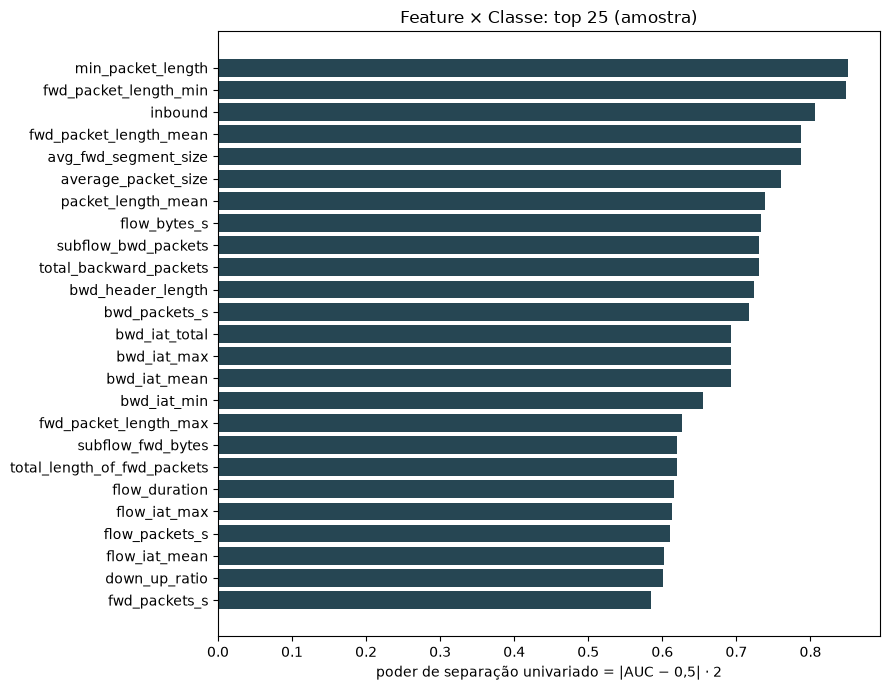

In [26]:
fig, ax = plt.subplots(figsize=(9, 7))
top = cmp_.head(25).sort_values("separacao")
ax.barh(top.index, top["separacao"], color="#264653")
ax.set_xlabel("poder de separação univariado = |AUC − 0,5| · 2")
ax.set_title("Feature × Classe: top 25 (amostra)")
salvar_fig("11_separacao_univariada")

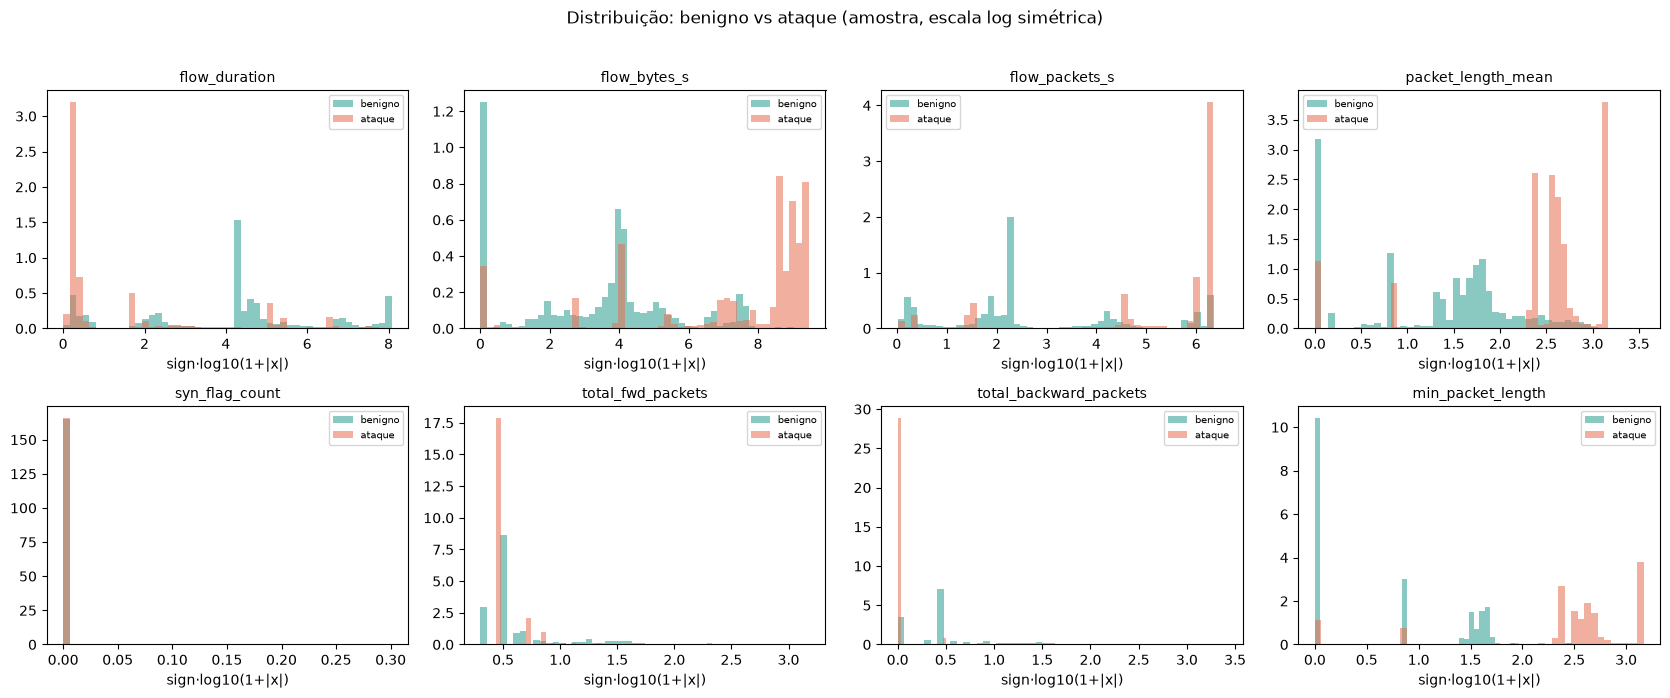

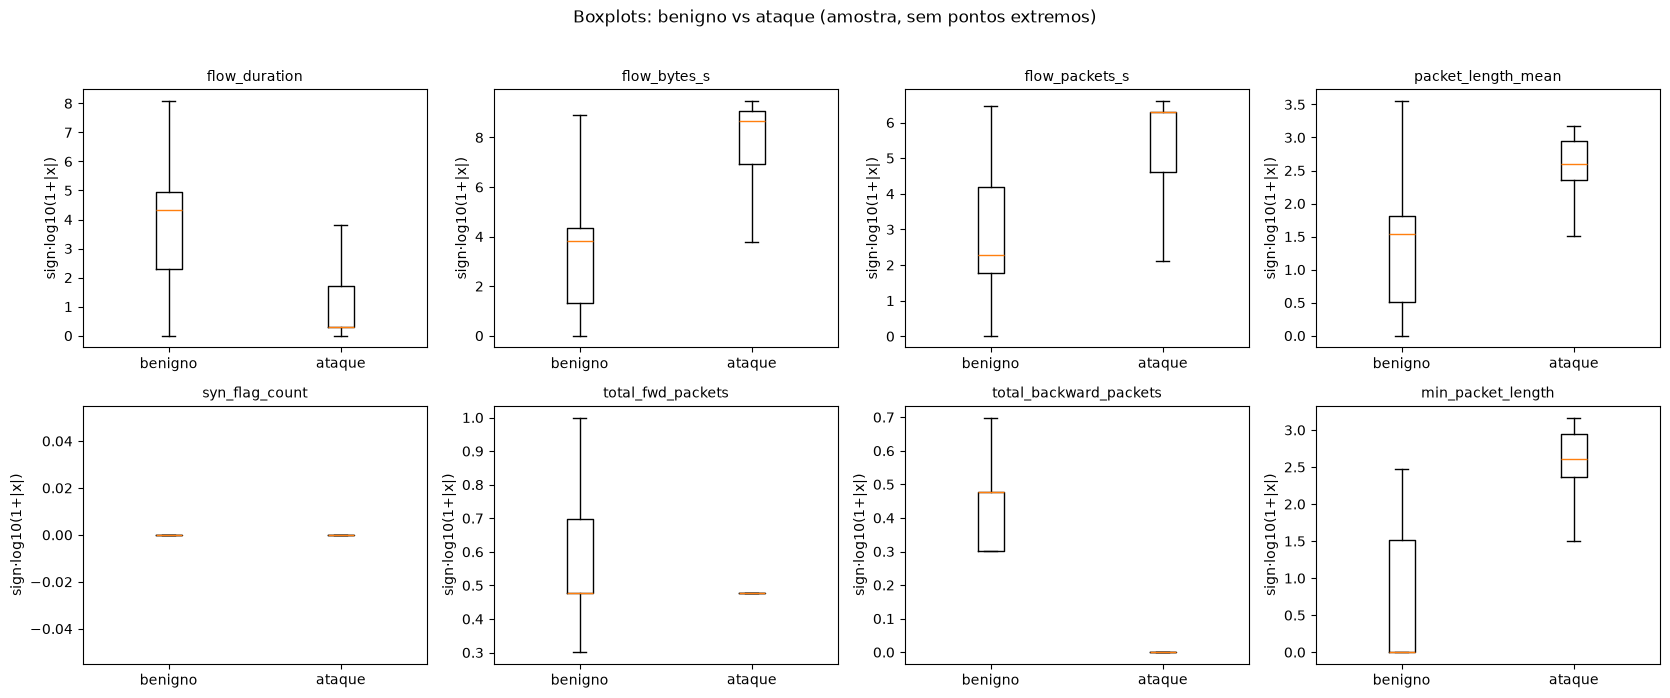

In [27]:
CHAVE = ["flow_duration", "flow_bytes_s", "flow_packets_s", "packet_length_mean",
         "syn_flag_count", "total_fwd_packets", "total_backward_packets"]
CHAVE = [c for c in CHAVE if c in FEATURES]
# completa com as mais separadoras, até 8 painéis
for c in cmp_.index:
    if len(CHAVE) >= 8:
        break
    if c not in CHAVE and pd.notna(cmp_.loc[c, "auc"]):
        CHAVE.append(c)


def slog(x):  # log simétrico: preserva sinal e lida com zeros
    return np.sign(x) * np.log10(1 + np.abs(x))


def painel(funcao, nome, titulo):
    ncols = 4
    nrows = int(np.ceil(len(CHAVE) / ncols))
    fig, axs = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.4 * nrows))
    for ax, c in zip(np.ravel(axs), CHAVE):
        funcao(ax, c)
        ax.set_title(c, fontsize=10)
    for ax in np.ravel(axs)[len(CHAVE):]:
        ax.axis("off")
    fig.suptitle(titulo, y=1.02)
    salvar_fig(nome)


def hist(ax, c):
    for g, cor in [("benigno", "#2a9d8f"), ("ataque", "#e76f51")]:
        v = slog(amostra.loc[amostra.grupo == g, c].dropna())
        if len(v):
            ax.hist(v, bins=50, alpha=0.55, density=True, color=cor, label=g)
    ax.set_xlabel("sign·log10(1+|x|)")
    ax.legend(fontsize=7)


def box(ax, c):
    dados = [slog(amostra.loc[amostra.grupo == g, c].dropna()) for g in ["benigno", "ataque"]]
    ax.boxplot(dados, showfliers=False)
    ax.set_xticks([1, 2]); ax.set_xticklabels(["benigno", "ataque"])
    ax.set_ylabel("sign·log10(1+|x|)")


painel(hist, "11_histogramas", "Distribuição: benigno vs ataque (amostra, escala log simétrica)")
painel(box, "11_boxplots", "Boxplots: benigno vs ataque (amostra, sem pontos extremos)")

In [28]:
# Perfil por classe (mediana das features-chave, dataset de amostra) — mostra se cada ataque tem "assinatura" própria
perfil = amostra.groupby("label")[CHAVE].median()
display(perfil)

,flow_duration,flow_bytes_s,flow_packets_s,packet_length_mean,syn_flag_count,total_fwd_packets,total_backward_packets,min_packet_length
label,,,,,,,,
BENIGN,"20,911.5000","6,509.9928",191.7270,33.8000,0.0000,2.0000,2.0000,0.0000
DrDoS_DNS,1.0000,"2,944,000,000.0000","2,000,000.0000","1,472.0000",0.0000,2.0000,0.0000,"1,472.0000"
DrDoS_LDAP,1.0000,"2,944,000,000.0000","2,000,000.0000","1,472.0000",0.0000,2.0000,0.0000,"1,472.0000"
DrDoS_MSSQL,1.0000,"916,000,000.0000","2,000,000.0000",484.0000,0.0000,2.0000,0.0000,484.0000
DrDoS_NTP,"1,002.0000","18,221,974.2639","42,946.8308",440.0000,0.0000,40.0000,0.0000,440.0000
DrDoS_NetBIOS,1.0000,"458,000,000.0000","2,000,000.0000",229.0000,0.0000,2.0000,0.0000,229.0000
DrDoS_SNMP,2.0000,"1,472,000,000.0000","1,000,000.0000","1,472.0000",0.0000,2.0000,0.0000,"1,472.0000"
DrDoS_SSDP,51.0000,"7,797,101.4493","17,751.4793",375.0000,0.0000,4.0000,0.0000,375.0000
DrDoS_UDP,65.5000,"1,002,203.0843","3,612.5536",372.0000,0.0000,4.0000,0.0000,366.0000


## 12. Resumo final da EDA (as 10 análises principais)

In [29]:
t = duplicatas[duplicatas.tabela == "TOTAL"].iloc[0]
maior = distribuicao.iloc[0]
menor = distribuicao.iloc[-1]

resumo = pd.DataFrame([
    (1, "Dimensão do dataset", f"{len(TABELAS)} tabelas | {TOTAL_REGISTROS:,} registros | {len(COLUNAS_COMUNS)} colunas | {len(FEATURES)} features candidatas"),
    (2, "Registros por classe", f"{len(distribuicao)} classes | maior: {maior.label_norm} ({int(maior.registros):,}) | menor: {menor.label_norm} ({int(menor.registros):,}) | benigno {n_ben:,} vs ataque {n_atk:,}"),
    (3, "Tipos das features", "declarado: " + ", ".join(sorted(set(tipos_declarados.tipo))) + " | inferido: " + "; ".join(f"{k}={v}" for k, v in inferido.tipo_inferido.value_counts().items())),
    (4, "Valores nulos/vazios", f"{int((qual_global['vazio'] > 0).sum())} features com vazios ({int(qual_global['vazio'].sum()):,} células)"),
    (5, "NaN / ±Inf / não numéricos", f"NaN={int(qual_global['nan'].sum()):,} | +Inf={int(qual_global['pos_inf'].sum()):,} | -Inf={int(qual_global['neg_inf'].sum()):,} | não numérico={int(qual_global['nao_numerico'].sum()):,} | linhas afetadas={int(linhas_afetadas.linhas_afetadas.sum()):,}"),
    (6, "Duplicatas (features+label)", f"{t.dup_C_features_label:,.0f} ({t.dup_C_features_label / t.registros:.2%}) | sem índice: {t.dup_B_sem_indice:,.0f} | labels conflitantes: {t.conflito_registros:,.0f} registros"),
    (7, "Features constantes", f"{int(var.constante.sum())} constantes, {int(var.sem_valor_valido.sum())} sem valor válido, {int(var.quase_constante.sum())} quase constantes, {int(var.binaria.sum())} binárias"),
    (8, "Estatísticas descritivas", "tabela completa em eda_outputs/07_estatisticas_long.csv"),
    (9, "Correlação", f"{len(pares_altos)} pares com |r| > {LIMIAR_CORR} | {len(candidatas)} features redundantes candidatas"),
    (10, "Distribuição / Feature×Classe", "top separadoras: " + ", ".join(cmp_.head(5).index)),
], columns=["Nº", "Análise", "Resultado"])

pd.set_option("display.max_colwidth", 200)
display(resumo)
resumo.to_csv(OUT / "resumo_eda.csv", index=False)
print("Arquivos em:", OUT)

,Nº,Análise,Resultado
0,1,Dimensão do dataset,"18 tabelas | 70,427,637 registros | 88 colunas | 80 features candidatas"
1,2,Registros por classe,"19 classes | maior: TFTP (20,082,580) | menor: WebDDoS (439) | benigno 113,828 vs ataque 70,313,809"
2,3,Tipos das features,declarado: String | inferido: numérico (inteiro)=46; numérico (decimal)=33; texto/misto=1
3,4,Valores nulos/vazios,"1 features com vazios (249,152 células)"
4,5,NaN / ±Inf / não numéricos,"NaN=0 | +Inf=4,092,348 | -Inf=0 | não numérico=6,145 | linhas afetadas=2,170,750"
5,6,Duplicatas (features+label),"59,927,555 (67.10%) | sem índice: 19,364,719 | labels conflitantes: nan registros"
6,7,Features constantes,"13 constantes, 0 sem valor válido, 0 quase constantes, 7 binárias"
7,8,Estatísticas descritivas,tabela completa em eda_outputs/07_estatisticas_long.csv
8,9,Correlação,47 pares com |r| > 0.95 | 25 features redundantes candidatas
9,10,Distribuição / Feature×Classe,"top separadoras: min_packet_length, fwd_packet_length_min, inbound, fwd_packet_length_mean, avg_fwd_segment_size"


Arquivos em: C:\Users\Bruno\downloads\tcc_codigo\railway-ch\eda_outputs
